In [51]:
%pip install pandas seaborn

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [52]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
plt.rcParams.update({"font.size": 16})
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["lines.linewidth"] = 1

In [53]:
serial_df = pd.read_csv('../serial/results.csv')
omp_df = pd.read_csv('../openmp/results.csv')
mpi_df = pd.read_csv('../mpi/results.csv')
cuda_df = pd.read_csv('../cuda/results.csv')
addn_df = pd.read_csv('../additional/results.csv')
jax_gpu_df = addn_df[addn_df["backend"] == "gpu"].copy()
jax_cpu_df = addn_df[addn_df["backend"] == "cpu"].copy()

In [54]:
serial_col = "#000000"
omp_col = sns.color_palette("Blues", 6)
mpi_col = sns.color_palette("Reds", 6)
cuda_col = sns.color_palette("Greens", 6)
addn_col = sns.color_palette("Oranges", 6)

In [55]:
ns = np.array(sorted(serial_df["n"].unique()))

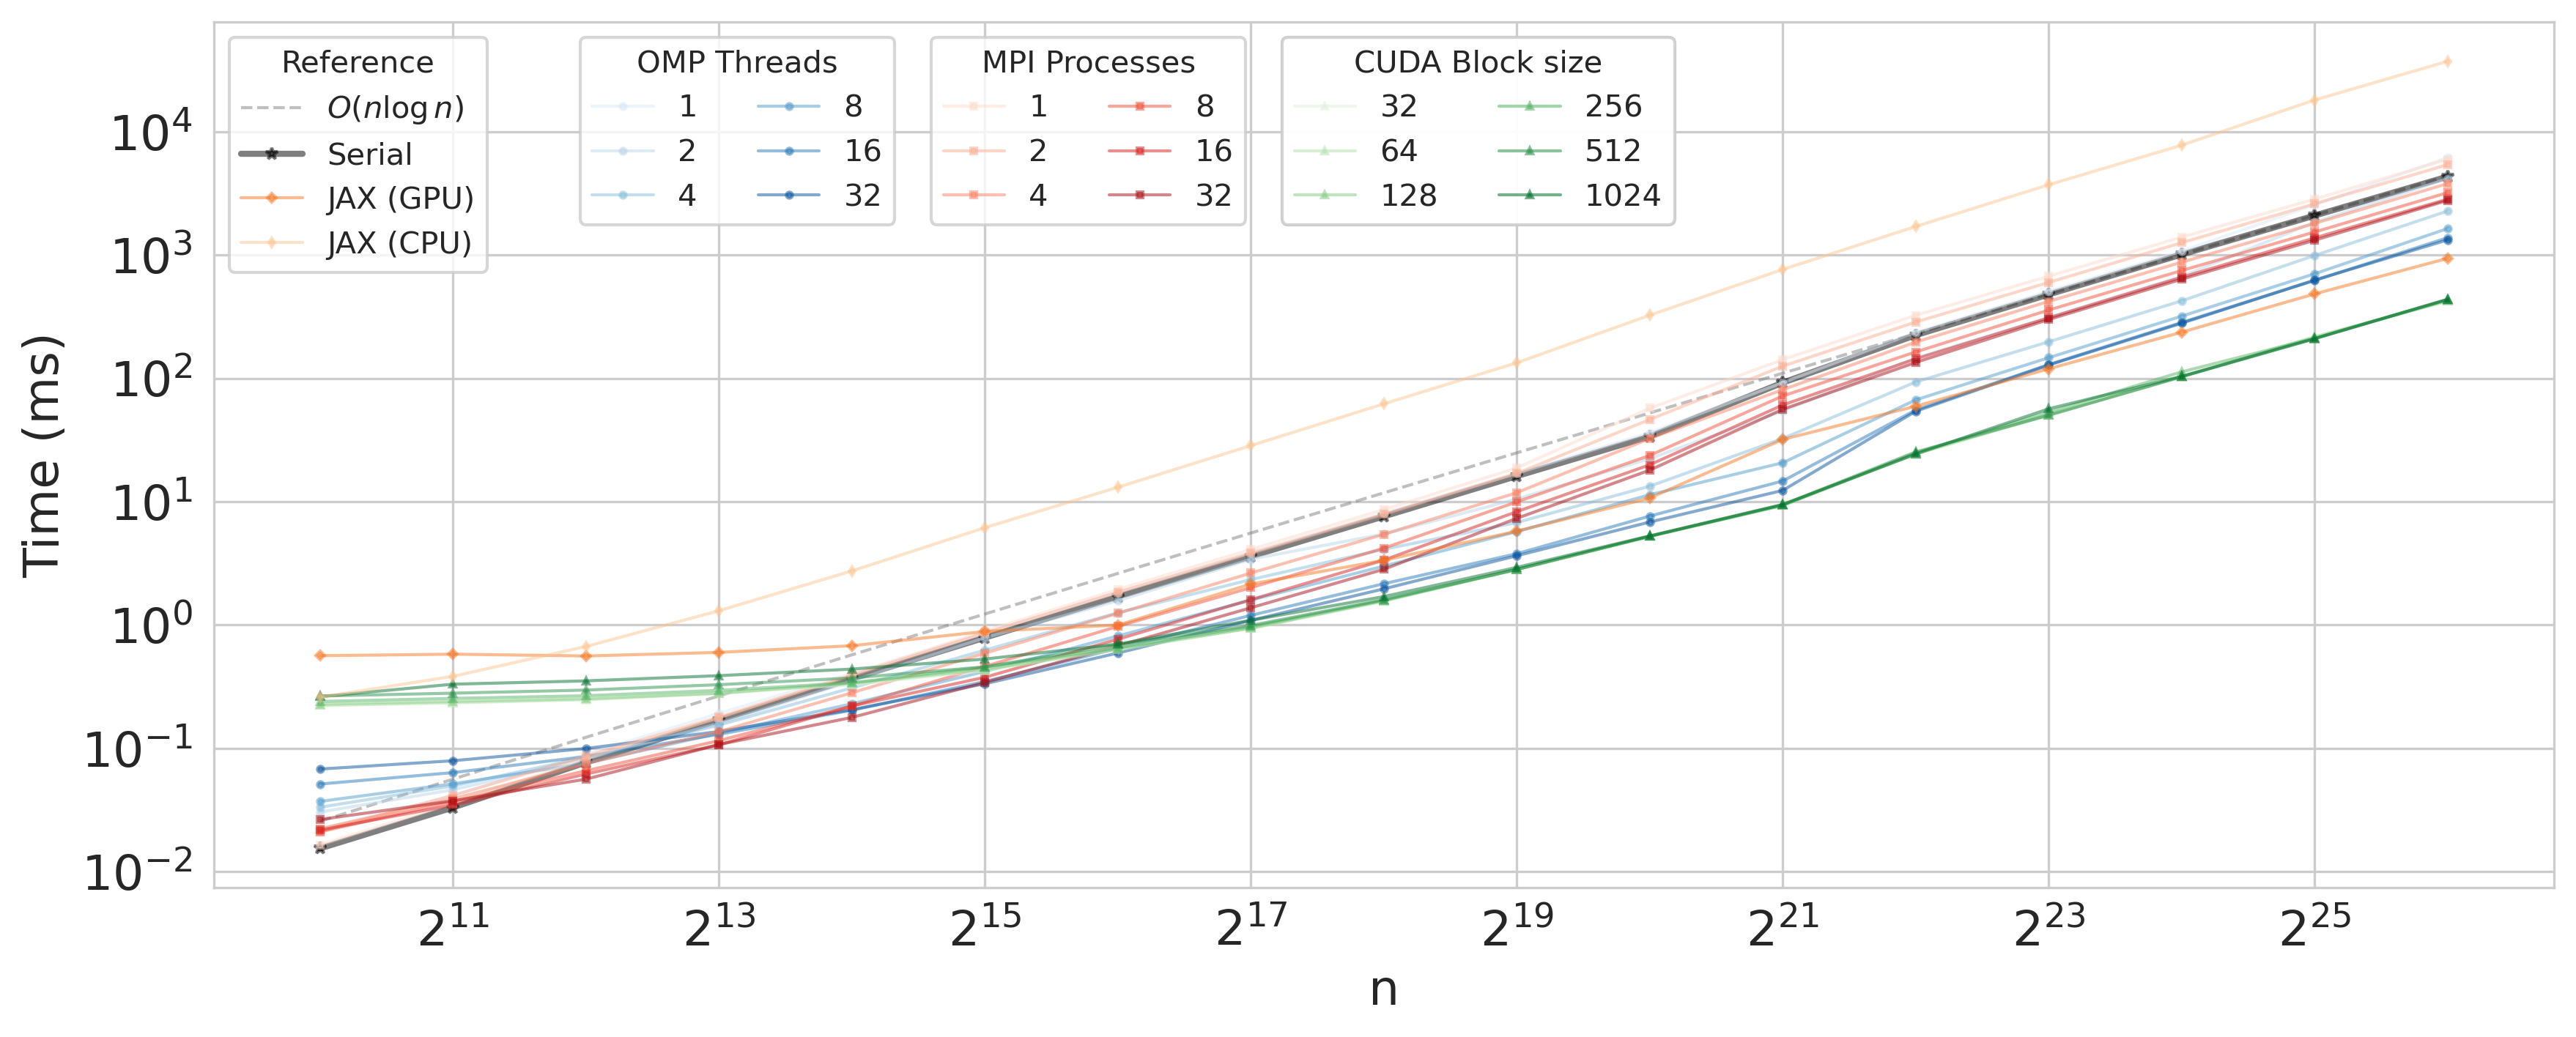

In [56]:
fig, ax = plt.subplots()

# --- plot each group ---
# reference
l_ref = ax.plot(
    ns,
    ns * np.log2(ns) * 2.5e-6,
    color="gray",
    linestyle="--",
    alpha=0.5,
    label="$O(n \\log n)$",
)[0]
l_serial = ax.plot(
    serial_df["n"],
    serial_df["time_ms"],
    color=serial_col,
    linewidth=2,
    alpha=0.5,
    marker="*",
    markersize=4,
    label="Serial",
)[0]

# openmp
omp_handles = []
for i, t in enumerate(sorted(omp_df["threads"].unique())):
    sub = omp_df[omp_df["threads"] == t]
    (h,) = ax.plot(
        sub["n"],
        sub["time_ms"],
        color=omp_col[i],
        alpha=0.5,
        marker="o",
        markersize=2,
    )
    omp_handles.append(h)

# mpi
mpi_handles = []
for i, p in enumerate(sorted(mpi_df["processes"].unique())):
    sub = mpi_df[mpi_df["processes"] == p]
    (h,) = ax.plot(
        sub["n"],
        sub["time_ms"],
        color=mpi_col[i],
        alpha=0.5,
        marker="s",
        markersize=2,
    )
    mpi_handles.append(h)

# cuda
cuda_handles = []
for i, bs in enumerate(sorted(cuda_df["block_size"].unique())):
    sub = cuda_df[cuda_df["block_size"] == bs]
    (h,) = ax.plot(
        sub["n"],
        sub["time_ms"],
        color=cuda_col[i],
        alpha=0.5,
        marker="^",
        markersize=2,
    )
    cuda_handles.append(h)

# jax
l_jax_gpu = ax.plot(
    jax_gpu_df["n"],
    jax_gpu_df["time_ms"],
    color=addn_col[3],
    alpha=0.5,
    marker="D",
    markersize=2,
    label="JAX (GPU)",
)[0]
l_jax_cpu = ax.plot(
    jax_cpu_df["n"],
    jax_cpu_df["time_ms"],
    color=addn_col[1],
    alpha=0.5,
    marker="d",
    markersize=2,
    label="JAX (CPU)",
)[0]

ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("n")
ax.set_ylabel("Time (ms)")

# --- separate legends ---
fs = 10

# reference + jax (top left)
leg1 = ax.legend(
    handles=[l_ref, l_serial, l_jax_gpu, l_jax_cpu],
    fontsize=fs,
    loc="upper left",
    title="Reference",
    title_fontsize=fs,
)
ax.add_artist(leg1)

# openmp
leg2_labels = [str(t) for t in sorted(omp_df["threads"].unique())]
leg2 = ax.legend(
    handles=omp_handles,
    labels=leg2_labels,
    fontsize=fs,
    bbox_to_anchor=(0.15, 1.0),
    loc="upper left",
    title="OMP Threads",
    title_fontsize=fs,
    ncol=2,
)
ax.add_artist(leg2)

# mpi
leg3_labels = [str(p) for p in sorted(mpi_df["processes"].unique())]
leg3 = ax.legend(
    handles=mpi_handles,
    labels=leg3_labels,
    fontsize=fs,
    bbox_to_anchor=(0.30, 1.0),
    loc="upper left",
    title="MPI Processes",
    title_fontsize=fs,
    ncol=2,
)
ax.add_artist(leg3)

# cuda
leg4_labels = [str(bs) for bs in sorted(cuda_df["block_size"].unique())]
leg4 = ax.legend(
    handles=cuda_handles,
    labels=leg4_labels,
    fontsize=fs,
    bbox_to_anchor=(0.45, 1.0),
    loc="upper left",
    title="CUDA Block size",
    title_fontsize=fs,
    ncol=2,
)
ax.add_artist(leg4)

plt.tight_layout()
plt.savefig("plots/overview.svg")
plt.show()

In [74]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, display
import os

stage_labels = [
    "Reference only",
    "Add Serial and JAX",
    "Add OpenMP",
    "Add MPI",
    "Add CUDA",
]

STAGE_BUFFER = 5
TOTAL_FRAMES = STAGE_BUFFER + len(stage_labels) * (len(ns) + STAGE_BUFFER)


def draw_overview_stage(ax, frame):
    ax.clear()
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("n")
    ax.set_ylabel("Time (ms)")
    ax.set_title("Results overview")

    stage = max((frame - STAGE_BUFFER) // (len(ns) + STAGE_BUFFER), 0)
    n = (frame - STAGE_BUFFER) % (len(ns) + STAGE_BUFFER)

    ax.text(
        0.92,
        0.98,
        f"Stage {stage + 1}/{len(stage_labels)}: {stage_labels[stage]}",
        transform=ax.transAxes,
        va="top",
        ha="right",
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8),
    )

    # reference
    l_ref = ax.plot(
        ns,
        ns * np.log2(ns) * 2.5e-6,
        color="gray",
        linestyle="--",
        alpha=0.5,
        label="$O(n \\log n)$",
    )[0]

    l_serial = None
    l_jax_gpu = None
    l_jax_cpu = None
    omp_handles = []
    mpi_handles = []
    cuda_handles = []

    if stage >= 1:
        l_serial = ax.plot(
            serial_df["n"][:n if stage == 1 else None],
            serial_df["time_ms"][:n if stage == 1 else None],
            color=serial_col,
            linewidth=2,
            alpha=0.5,
            marker="*",
            markersize=4,
            label="Serial",
        )[0]

        l_jax_gpu = ax.plot(
            jax_gpu_df["n"][:n if stage == 1 else None],
            jax_gpu_df["time_ms"][:n if stage == 1 else None],
            color=addn_col[3],
            alpha=0.5,
            marker="D",
            markersize=2,
            label="JAX (GPU)",
        )[0]
        l_jax_cpu = ax.plot(
            jax_cpu_df["n"][:n if stage == 1 else None],
            jax_cpu_df["time_ms"][:n if stage == 1 else None],
            color=addn_col[1],
            alpha=0.5,
            marker="d",
            markersize=2,
            label="JAX (CPU)",
        )[0]

    if stage >= 2:
        for i, t in enumerate(sorted(omp_df["threads"].unique())):
            sub = omp_df[omp_df["threads"] == t]
            (h,) = ax.plot(
                sub["n"][:n if stage == 2 else None],
                sub["time_ms"][:n if stage == 2 else None],
                color=omp_col[i],
                alpha=0.5,
                marker="o",
                markersize=2,
            )
            omp_handles.append(h)

    if stage >= 3:
        for i, p in enumerate(sorted(mpi_df["processes"].unique())):
            sub = mpi_df[mpi_df["processes"] == p]
            (h,) = ax.plot(
                sub["n"][:n if stage == 3 else None],
                sub["time_ms"][:n if stage == 3 else None],
                color=mpi_col[i],
                alpha=0.5,
                marker="s",
                markersize=2,
            )
            mpi_handles.append(h)

    if stage >= 4:
        for i, bs in enumerate(sorted(cuda_df["block_size"].unique())):
            sub = cuda_df[cuda_df["block_size"] == bs]
            (h,) = ax.plot(
                sub["n"][:n if stage == 4 else None],
                sub["time_ms"][:n if stage == 4 else None],
                color=cuda_col[i],
                alpha=0.5,
                marker="^",
                markersize=2,
            )
            cuda_handles.append(h)

    leg1_handles = [l_ref]
    leg1_labels = ["$O(n \\log n)$"]
    if l_serial is not None:
        leg1_handles.extend([l_serial, l_jax_gpu, l_jax_cpu])
        leg1_labels.extend(["Serial", "JAX (GPU)", "JAX (CPU)"])

    leg1 = ax.legend(
        handles=leg1_handles,
        labels=leg1_labels,
        fontsize=10,
        loc="upper left",
        title="Reference",
        title_fontsize=10,
    )
    ax.add_artist(leg1)

    if omp_handles:
        leg2_labels = [str(t) for t in sorted(omp_df["threads"].unique())]
        leg2 = ax.legend(
            handles=omp_handles,
            labels=leg2_labels,
            fontsize=10,
            bbox_to_anchor=(0.15, 1.0),
            loc="upper left",
            title="OMP Threads",
            title_fontsize=10,
            ncol=2,
        )
        ax.add_artist(leg2)

    if mpi_handles:
        leg3_labels = [str(p) for p in sorted(mpi_df["processes"].unique())]
        leg3 = ax.legend(
            handles=mpi_handles,
            labels=leg3_labels,
            fontsize=10,
            bbox_to_anchor=(0.33, 1.0),
            loc="upper left",
            title="MPI Processes",
            title_fontsize=10,
            ncol=2,
        )
        ax.add_artist(leg3)

    if cuda_handles:
        leg4_labels = [
            str(bs) for bs in sorted(cuda_df["block_size"].unique())
        ]
        leg4 = ax.legend(
            handles=cuda_handles,
            labels=leg4_labels,
            fontsize=10,
            bbox_to_anchor=(0.5, 1.0),
            loc="upper left",
            title="CUDA Block size",
            title_fontsize=10,
            ncol=2,
        )
        ax.add_artist(leg4)


os.makedirs("plots", exist_ok=True)
fig_anim, ax_anim = plt.subplots()
anim = FuncAnimation(
    fig_anim,
    lambda stage: draw_overview_stage(ax_anim, stage),
    frames=TOTAL_FRAMES,
    interval=1000 / len(ns),
    blit=False,
    repeat=True,
)

anim.save(
    "plots/overview_animation.gif", writer=PillowWriter(fps=len(ns)), dpi=150
)
plt.close(fig_anim)

# OMP

## Strong scaling

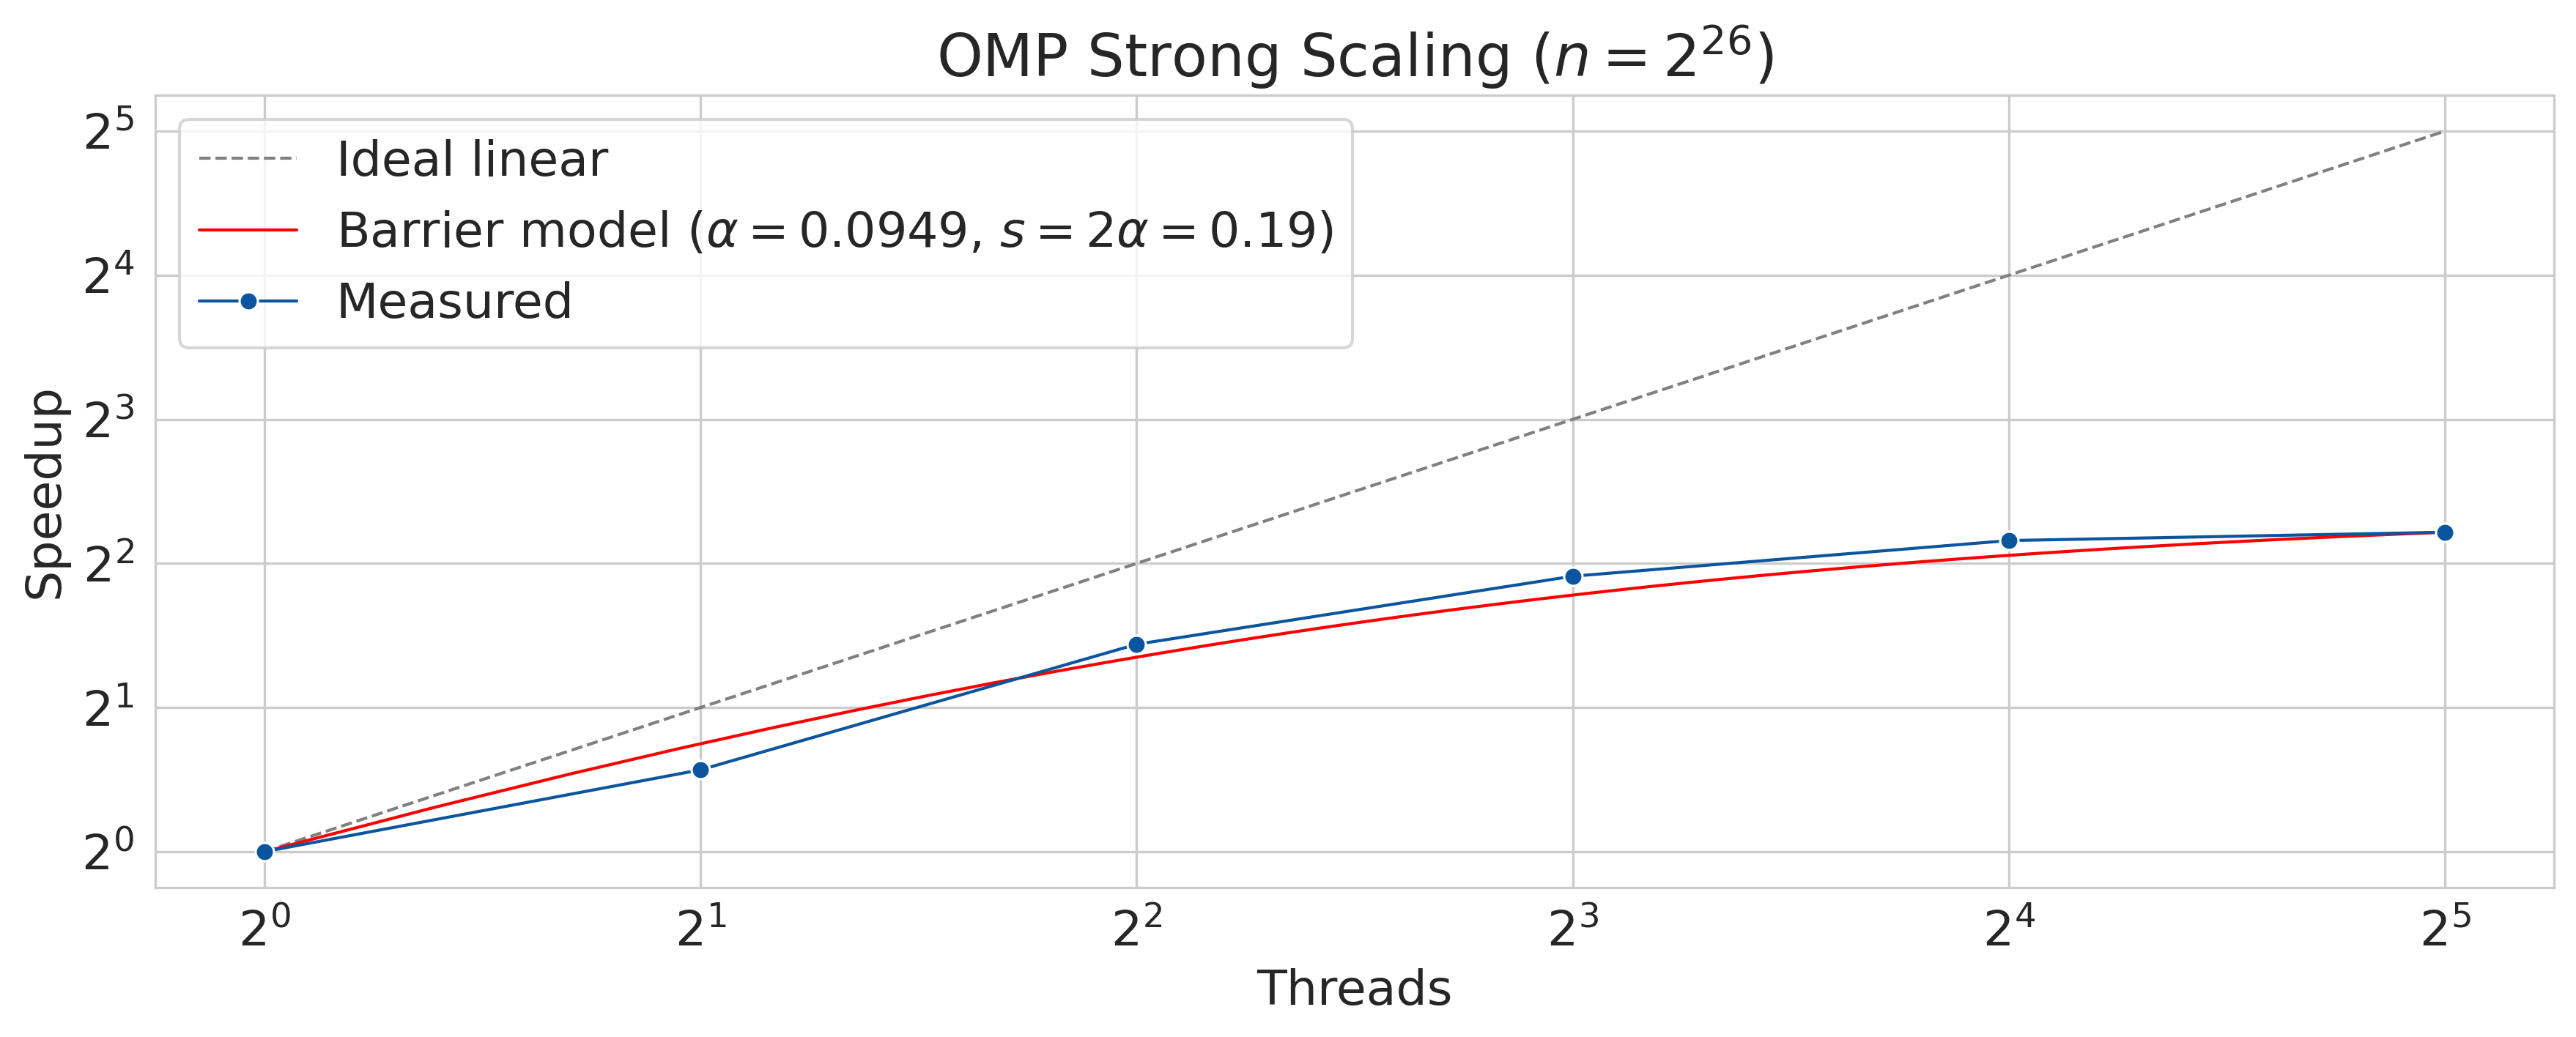

In [58]:
n_to_compare = max(omp_df["n"])
omp_strong_df = omp_df[omp_df["n"] == n_to_compare]
baseline = omp_strong_df[omp_strong_df["threads"] == 1]["time_ms"].values[0]

threads = np.array(sorted(omp_strong_df["threads"].unique()))
speedups = [
    baseline
    / omp_strong_df[omp_strong_df["threads"] == t]["time_ms"].values[0]
    for t in threads
]

# Barrier model: S(p) = p / (1 + 2(p-1) * alpha)
# Equivalent to Amdahl's law for fixed n, with s = 2*alpha
p_max = threads[-1]
alpha_omp = (p_max / speedups[-1] - 1) / (2 * (p_max - 1))
p_smooth = np.linspace(1, p_max, 100)
theoretical = p_smooth / (1 + 2 * (p_smooth - 1) * alpha_omp)

sns.lineplot(
    x=threads, y=threads, linestyle="--", color="gray", label="Ideal linear"
)
sns.lineplot(
    x=p_smooth,
    y=theoretical,
    linestyle="-",
    color="red",
    label=f"Barrier model ($\\alpha={alpha_omp:.4f}$, $s=2\\alpha={2*alpha_omp:.2f}$)",
)

sns.lineplot(
    x=threads, y=speedups, marker="o", color=omp_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.yscale("log", base=2)
plt.xlabel("Threads")
plt.ylabel("Speedup")
plt.title(f"OMP Strong Scaling ($n=2^{{{int(np.log2(n_to_compare))}}}$)")

plt.legend()
plt.tight_layout()
plt.savefig("plots/omp_strong.svg")
plt.show()

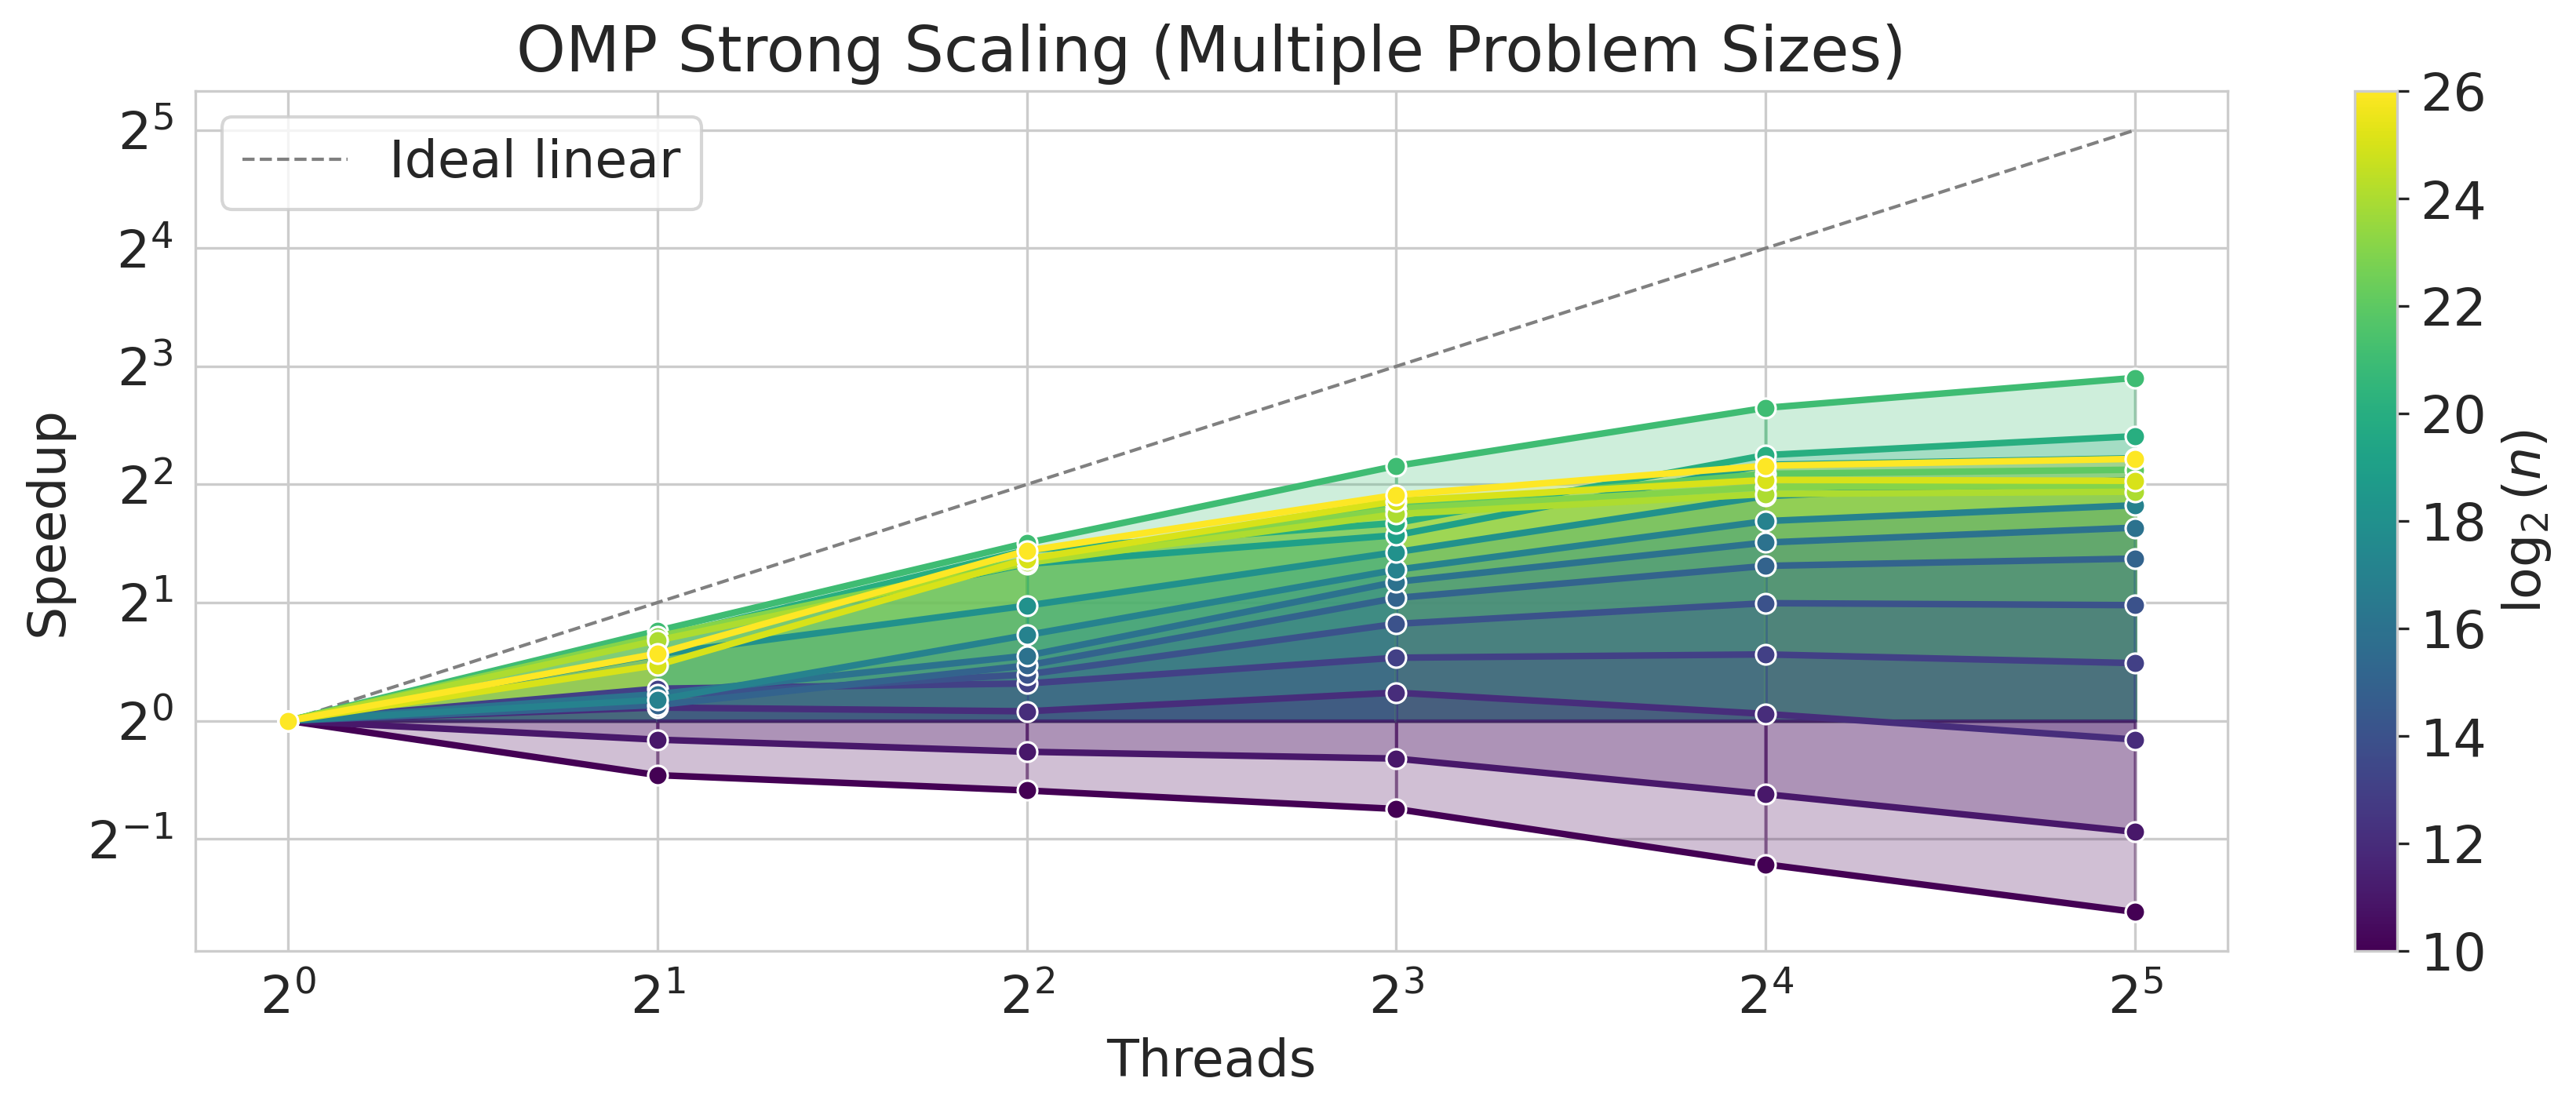

In [59]:
from plot_utils import (
    compute_multiscale_speedup_series,
    draw_multiscale_series,
)

fig, ax = plt.subplots()
ax.plot(
    sorted(omp_df["threads"].unique()),
    sorted(omp_df["threads"].unique()),
    linestyle="--",
    color="gray",
    label="Ideal linear",
)
series, groups_all, max_group, norm, cmap = compute_multiscale_speedup_series(
    omp_df, group_col="threads", n_col="n", time_col="time_ms"
)
draw_multiscale_series(
    ax,
    series,
    groups_all,
    cmap,
    norm,
    fill_y0=1,
    xlabel="Threads",
    ylabel="Speedup",
    title="OMP Strong Scaling (Multiple Problem Sizes)",
    cbar_label="$\\log_2(n)$",
    y_log=True,
    x_log=True,
    savepath="plots/omp_strong_multiscale.svg",
)

## Weak scaling

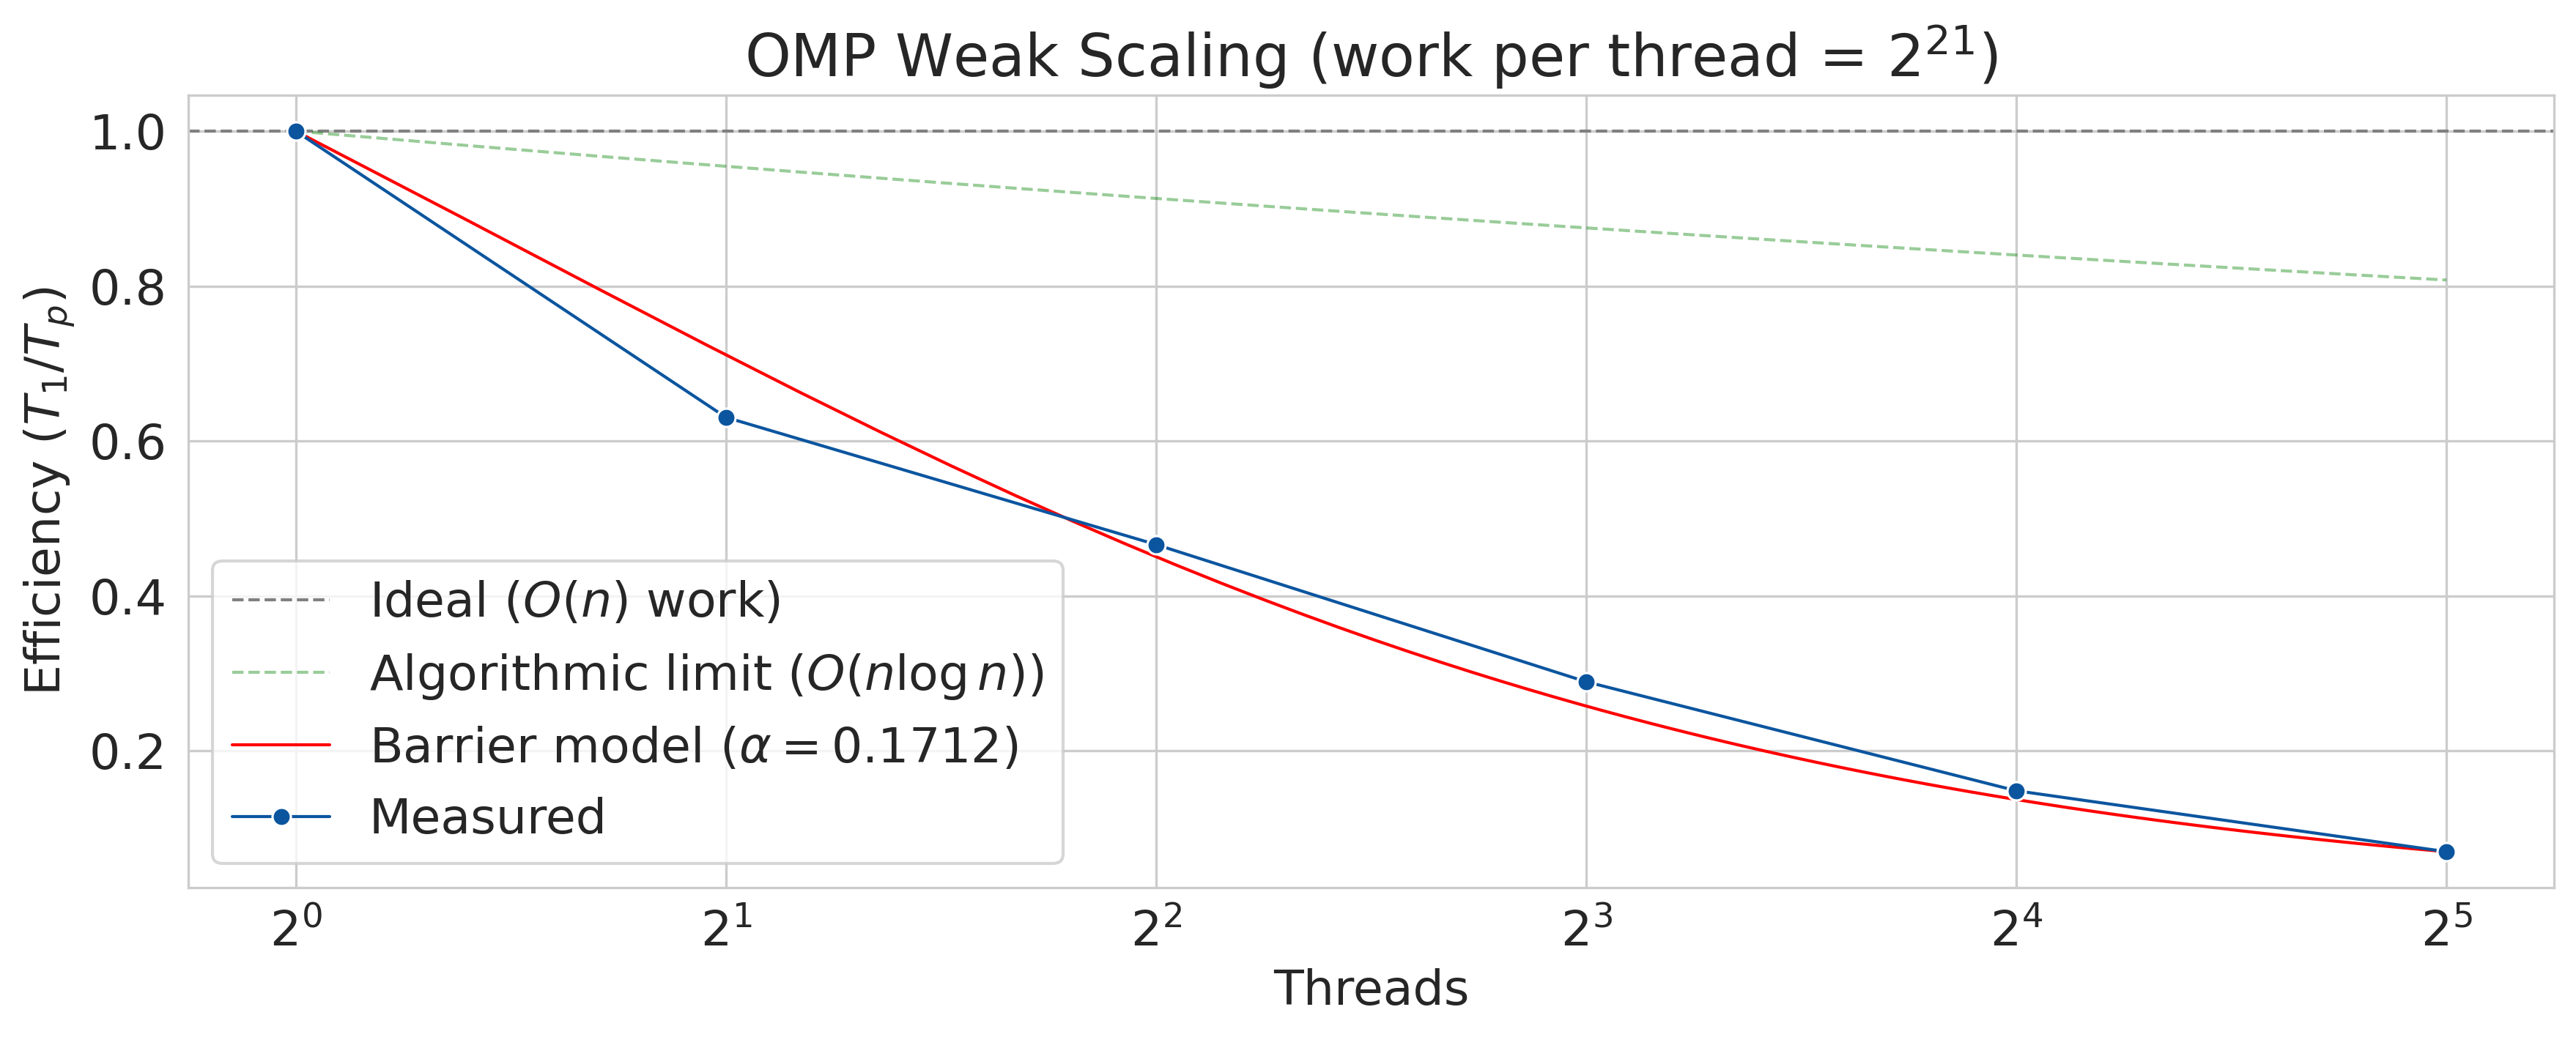

In [60]:
n_per_thread = int(n_to_compare / max(threads))
L = int(np.log2(n_per_thread))
baseline = omp_df[(omp_df["threads"] == 1) & (omp_df["n"] == n_per_thread)][
    "time_ms"
].values[0]

efficiency = [
    baseline
    / omp_df[(omp_df["threads"] == t) & (omp_df["n"] == t * n_per_thread)][
        "time_ms"
    ].values[0]
    for t in threads
]

# Algorithmic limit: E = L / (L + log2(p)), from O(n log n) work growth
p_smooth = np.linspace(1, max(threads), 100)
algorithmic = L / (L + np.log2(p_smooth))

# Barrier model: E(p) = L / [(L + log2(p)) * (1 + 2(p-1) * alpha)]
# Fit alpha from the max-thread measurement
p_max = threads[-1]
E_max = efficiency[-1]
alpha_weak = (L / (E_max * (L + np.log2(p_max))) - 1) / (2 * (p_max - 1))
barrier_model = L / (
    (L + np.log2(p_smooth)) * (1 + 2 * (p_smooth - 1) * alpha_weak)
)

plt.axhline(y=1, linestyle="--", color="gray", label="Ideal ($O(n)$ work)")
sns.lineplot(
    x=p_smooth,
    y=algorithmic,
    linestyle="--",
    color="green",
    alpha=0.4,
    label=f"Algorithmic limit ($O(n \\log n)$)",
)
sns.lineplot(
    x=p_smooth,
    y=barrier_model,
    linestyle="-",
    color="red",
    label=f"Barrier model ($\\alpha={alpha_weak:.4f}$)",
)

sns.lineplot(
    x=threads, y=efficiency, marker="o", color=omp_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.xlabel("Threads")
plt.ylabel("Efficiency ($T_1 / T_p$)")
plt.title(f"OMP Weak Scaling (work per thread = $2^{{{L}}}$)")
plt.legend()
plt.tight_layout()
plt.savefig("plots/omp_weak.svg")
plt.show()

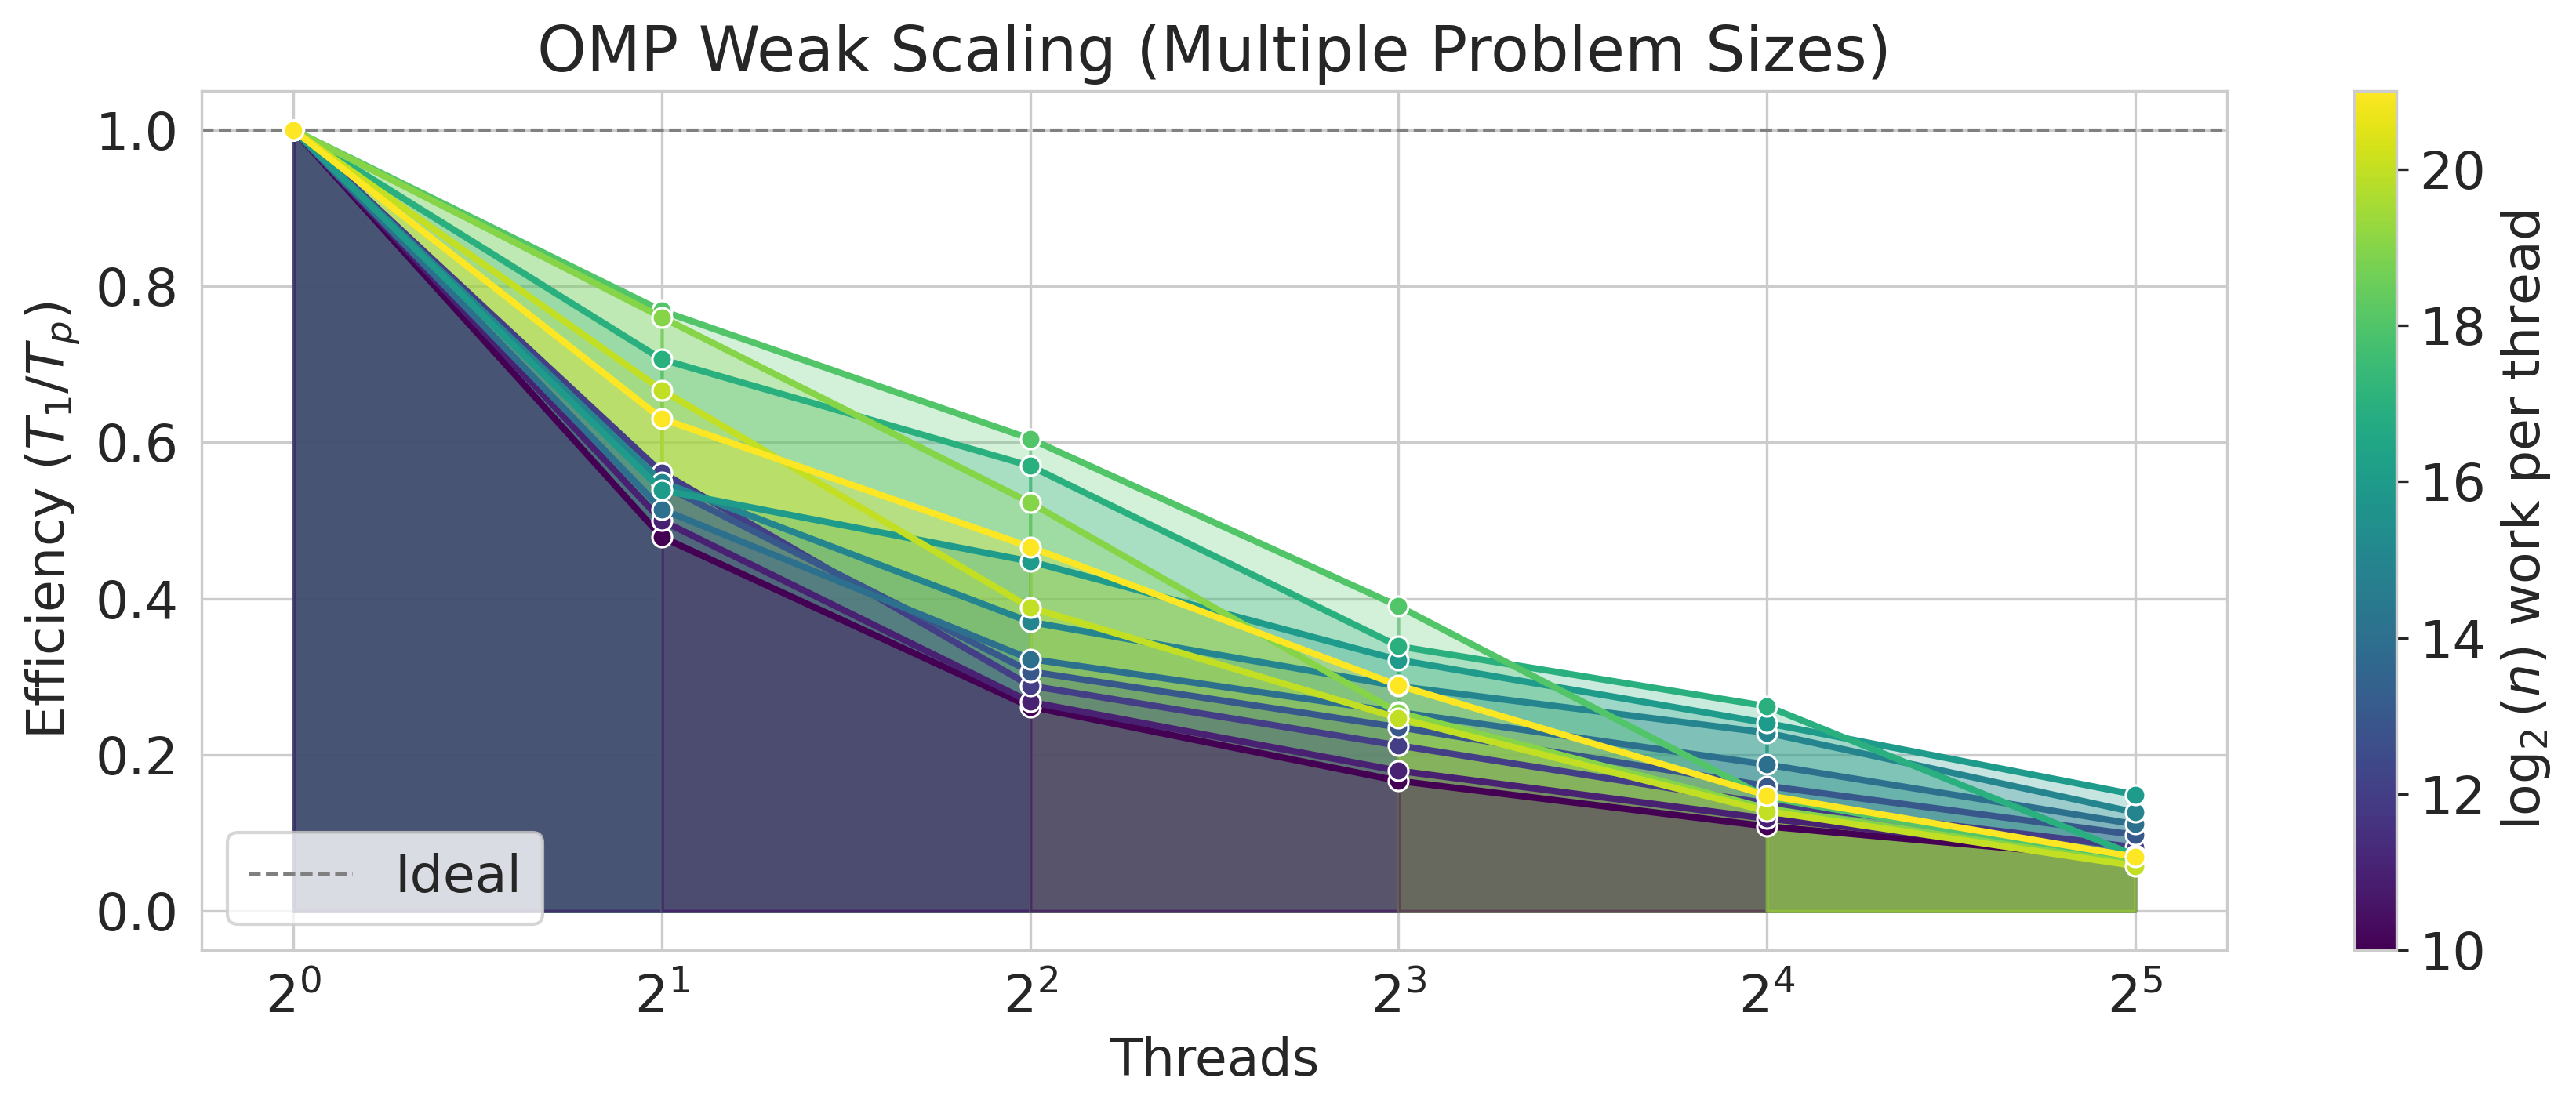

In [61]:
from plot_utils import (
    compute_multiscale_efficiency_series,
    draw_multiscale_series,
)

fig, ax = plt.subplots()
series, groups_all, max_group, norm, cmap = (
    compute_multiscale_efficiency_series(
        omp_df, group_col="threads", n_col="n", time_col="time_ms"
    )
)
draw_multiscale_series(
    ax,
    series,
    groups_all,
    cmap,
    norm,
    fill_y0=0,
    xlabel="Threads",
    ylabel="Efficiency ($T_1 / T_p$)",
    title="OMP Weak Scaling (Multiple Problem Sizes)",
    cbar_label="$\\log_2(n)$ work per thread",
    vline=1,
    savepath="plots/omp_weak_multiscale.svg",
)

## Speedup vs Serial

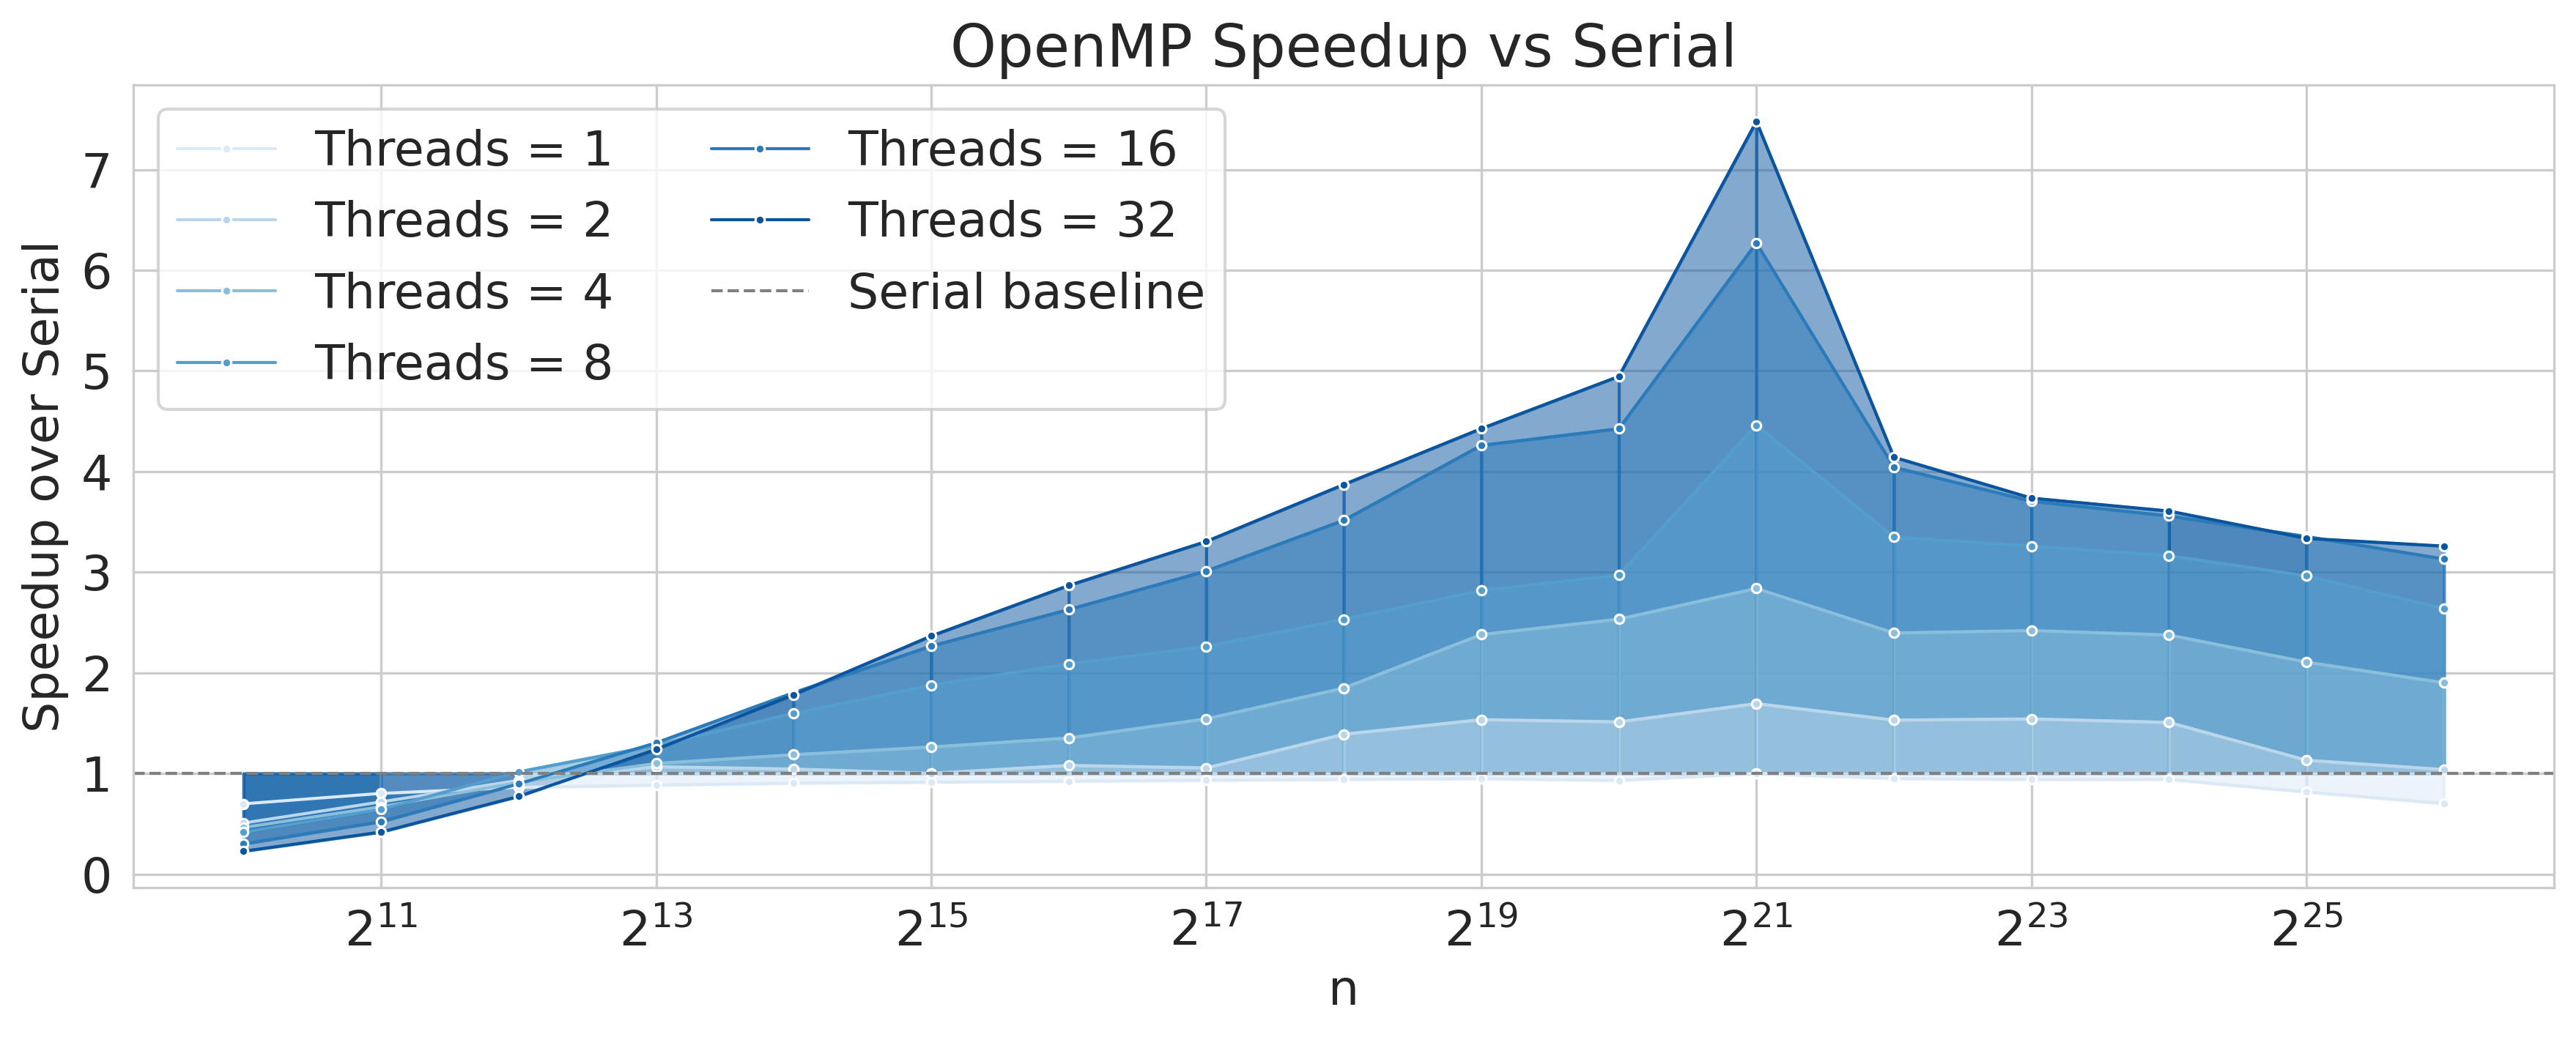

,threads,n,time_ms_impl,time_ms_serial,speedup
0,1,1024,0.022113,0.015444,0.698416
1,2,1024,0.030430,0.015444,0.507529
2,4,1024,0.033298,0.015444,0.463809
3,8,1024,0.037115,0.015444,0.416112
4,16,1024,0.051347,0.015444,0.300776
...,...,...,...,...,...
97,2,67108864,4161.230000,4325.570000,1.039493
98,4,67108864,2274.990000,4325.570000,1.901358
99,8,67108864,1639.690000,4325.570000,2.638041
100,16,67108864,1381.360000,4325.570000,3.131385


In [62]:
from plot_utils import plot_grouped_speedup_vs_serial

fig, ax = plt.subplots()
plot_grouped_speedup_vs_serial(
    ax,
    omp_df,
    serial_df,
    group_col="threads",
    colors=omp_col,
    marker="o",
    label_template="Threads = {value}",
    xlabel="n",
    ylabel="Speedup over Serial",
    title="OpenMP Speedup vs Serial",
    legend_kwargs={"ncol": 2},
    savepath="plots/omp_speedup.svg",
)

# MPI

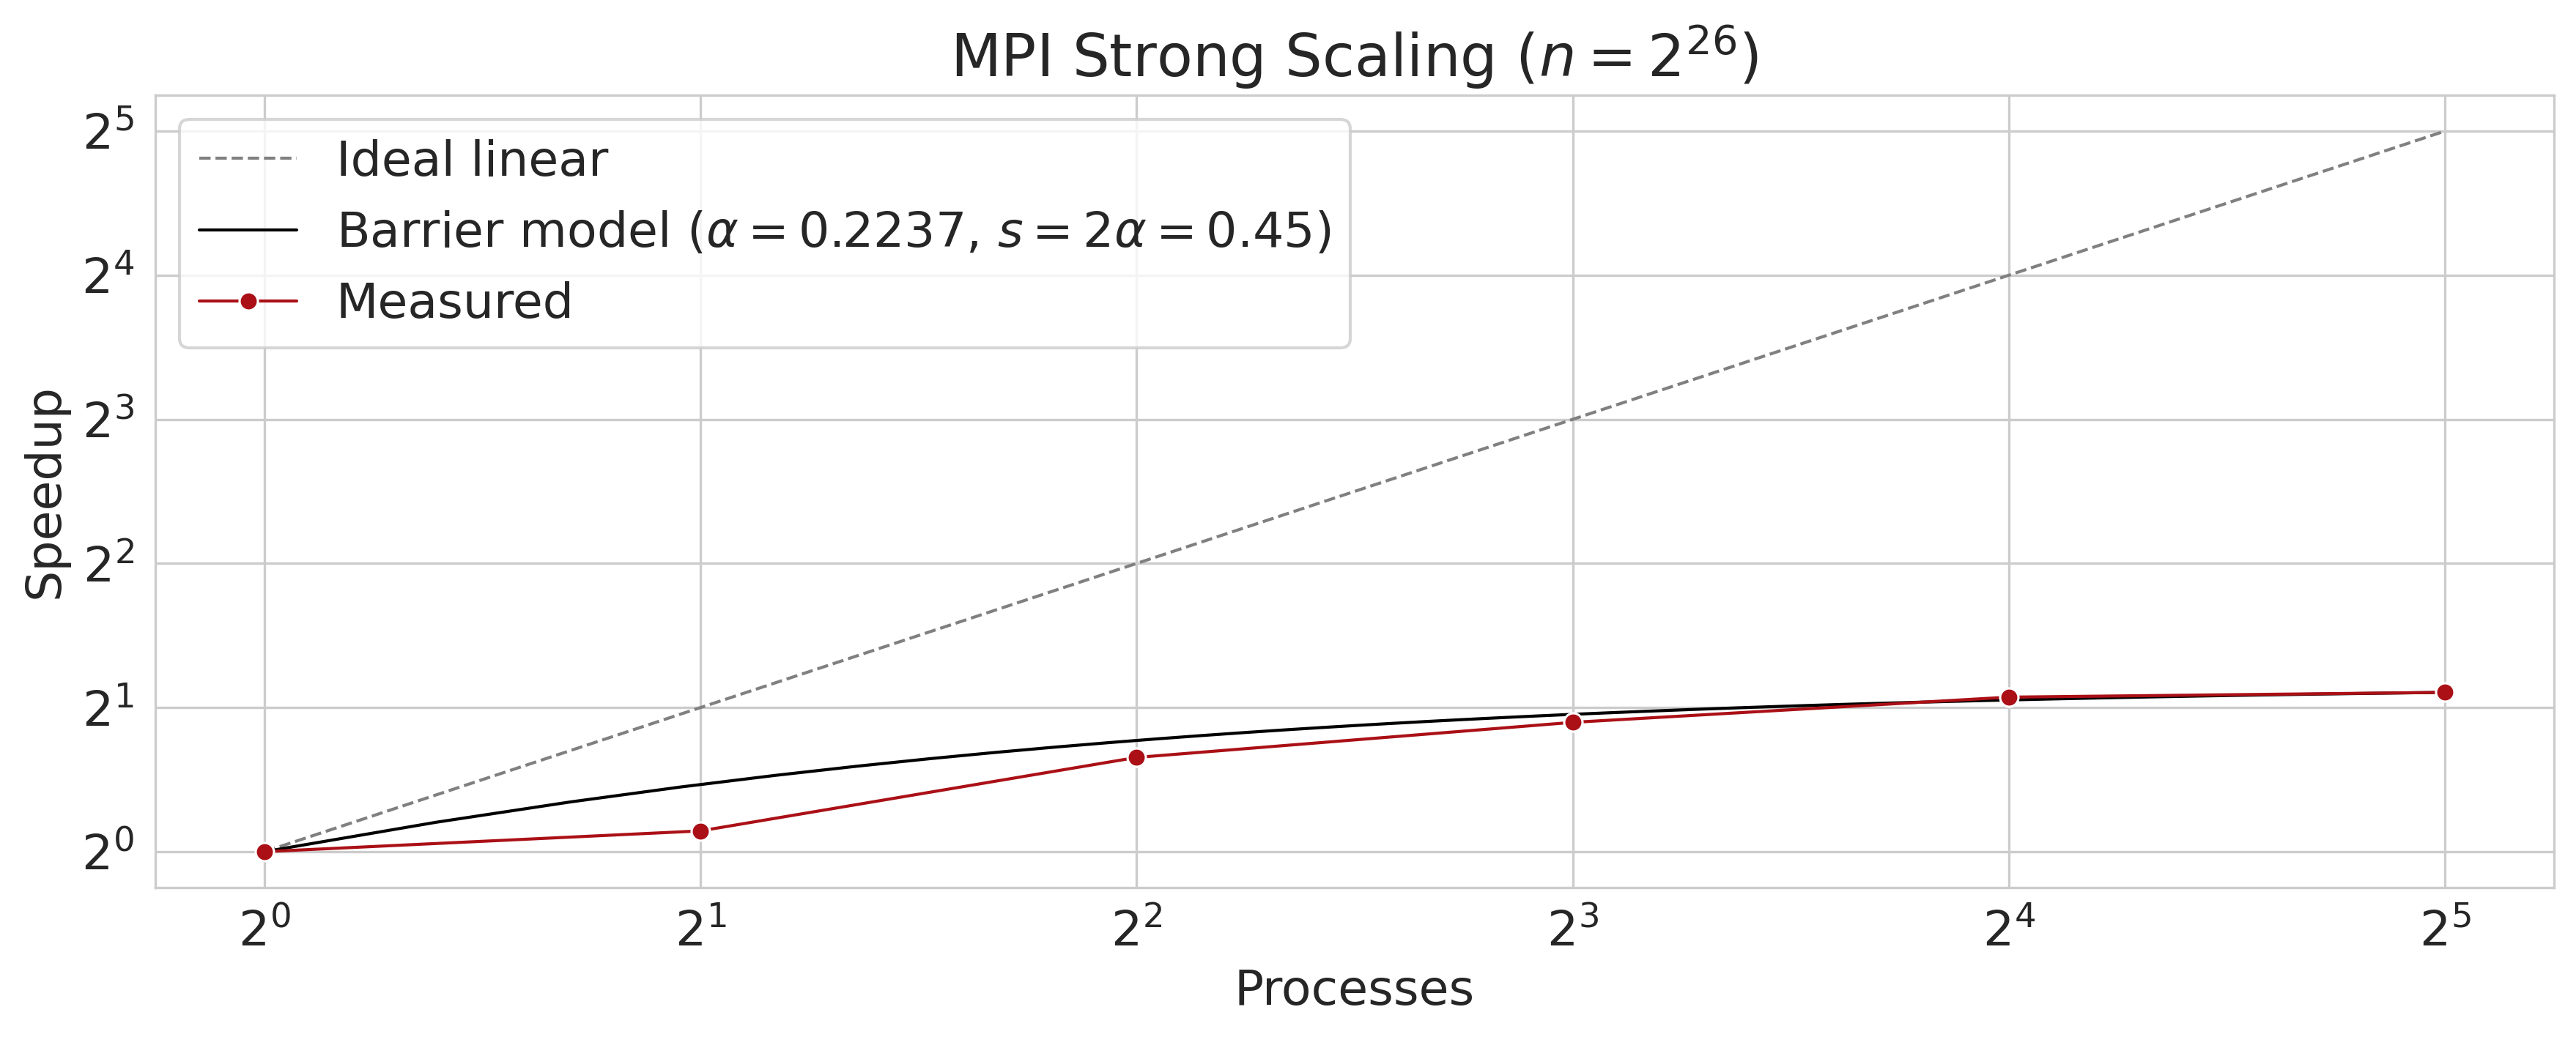

In [63]:
n_to_compare = max(mpi_df["n"])
mpi_strong_df = mpi_df[mpi_df["n"] == n_to_compare]
baseline = mpi_strong_df[mpi_strong_df["processes"] == 1]["time_ms"].values[0]

processes = np.array(sorted(mpi_strong_df["processes"].unique()))
speedups = [
    baseline
    / mpi_strong_df[mpi_strong_df["processes"] == t]["time_ms"].values[0]
    for t in processes
]

# Barrier model: S(p) = p / (1 + 2(p-1) * alpha)
p_max = processes[-1]
alpha_mpi = (p_max / speedups[-1] - 1) / (2 * (p_max - 1))
p_smooth = np.linspace(1, p_max, 100)
theoretical = p_smooth / (1 + 2 * (p_smooth - 1) * alpha_mpi)

plt.plot(
    processes, processes, linestyle="--", color="gray", label="Ideal linear"
)
plt.plot(
    p_smooth,
    theoretical,
    linestyle="-",
    color="black",
    label=f"Barrier model ($\\alpha={alpha_mpi:.4f}$, $s=2\\alpha={2*alpha_mpi:.2f}$)",
)

sns.lineplot(
    x=processes, y=speedups, marker="o", color=mpi_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.yscale("log", base=2)
plt.xlabel("Processes")
plt.ylabel("Speedup")
plt.title(f"MPI Strong Scaling ($n=2^{{{int(np.log2(n_to_compare))}}}$)")

plt.legend()
plt.tight_layout()
plt.savefig("plots/mpi_strong.svg")
plt.show()

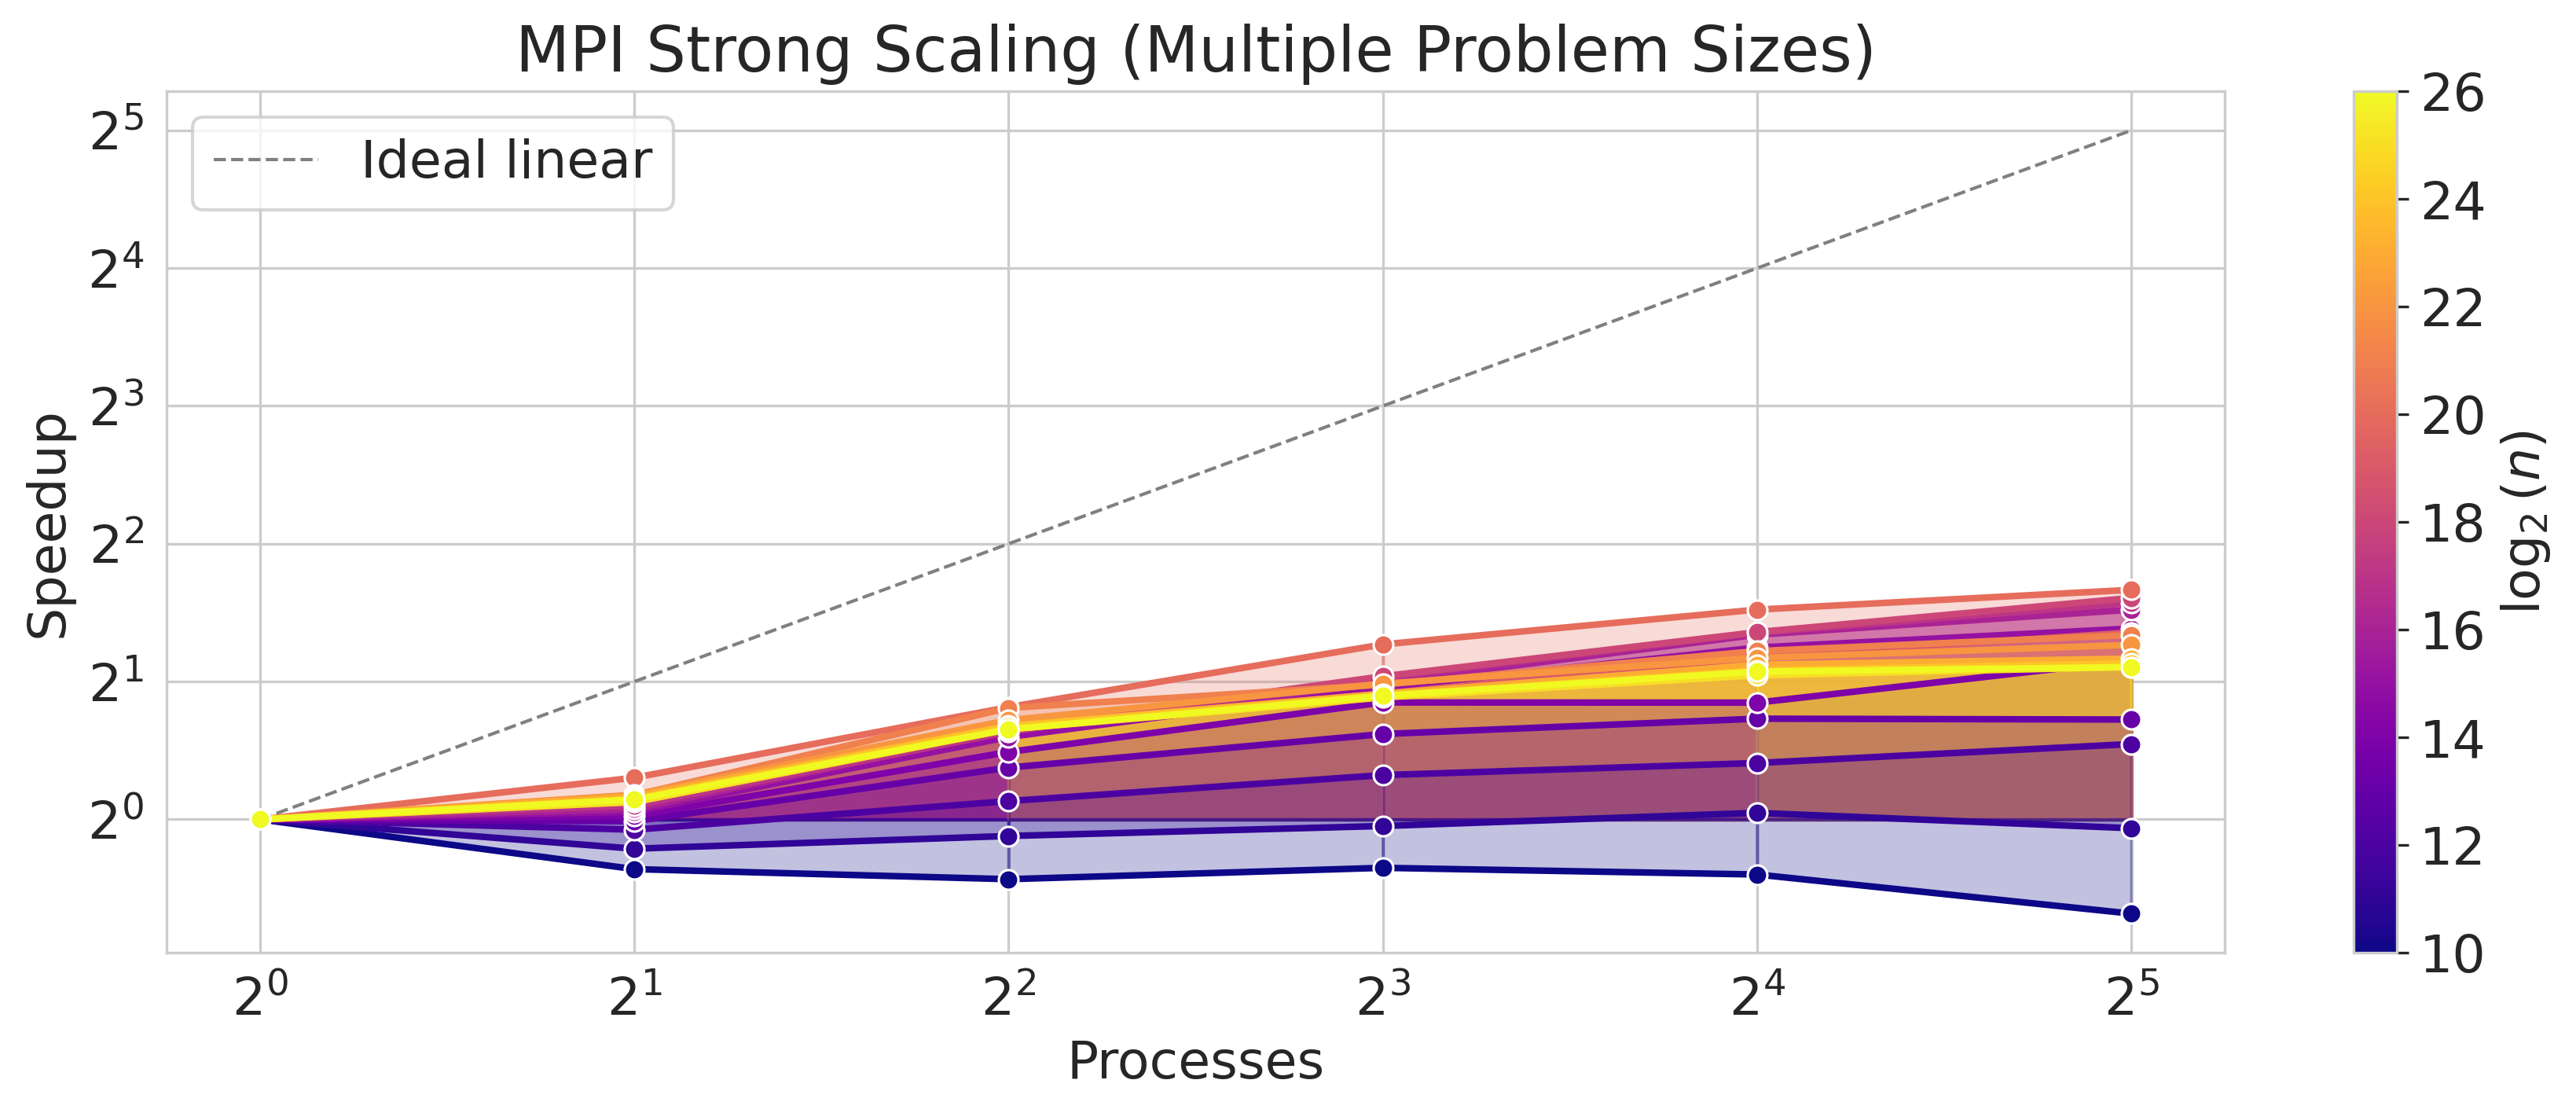

In [64]:
from plot_utils import (
    compute_multiscale_speedup_series,
    draw_multiscale_series,
)

fig, ax = plt.subplots()
ax.plot(
    sorted(mpi_df["processes"].unique()),
    sorted(mpi_df["processes"].unique()),
    linestyle="--",
    color="gray",
    label="Ideal linear",
)
series, groups_all, max_group, norm, cmap = compute_multiscale_speedup_series(
    mpi_df,
    group_col="processes",
    n_col="n",
    time_col="time_ms",
    cmap=plt.cm.plasma,
)
draw_multiscale_series(
    ax,
    series,
    groups_all,
    cmap,
    norm,
    fill_y0=1,
    xlabel="Processes",
    ylabel="Speedup",
    title="MPI Strong Scaling (Multiple Problem Sizes)",
    cbar_label="$\\log_2(n)$",
    y_log=True,
    x_log=True,
    savepath="plots/mpi_strong_multiscale.svg",
)

## Weak scaling

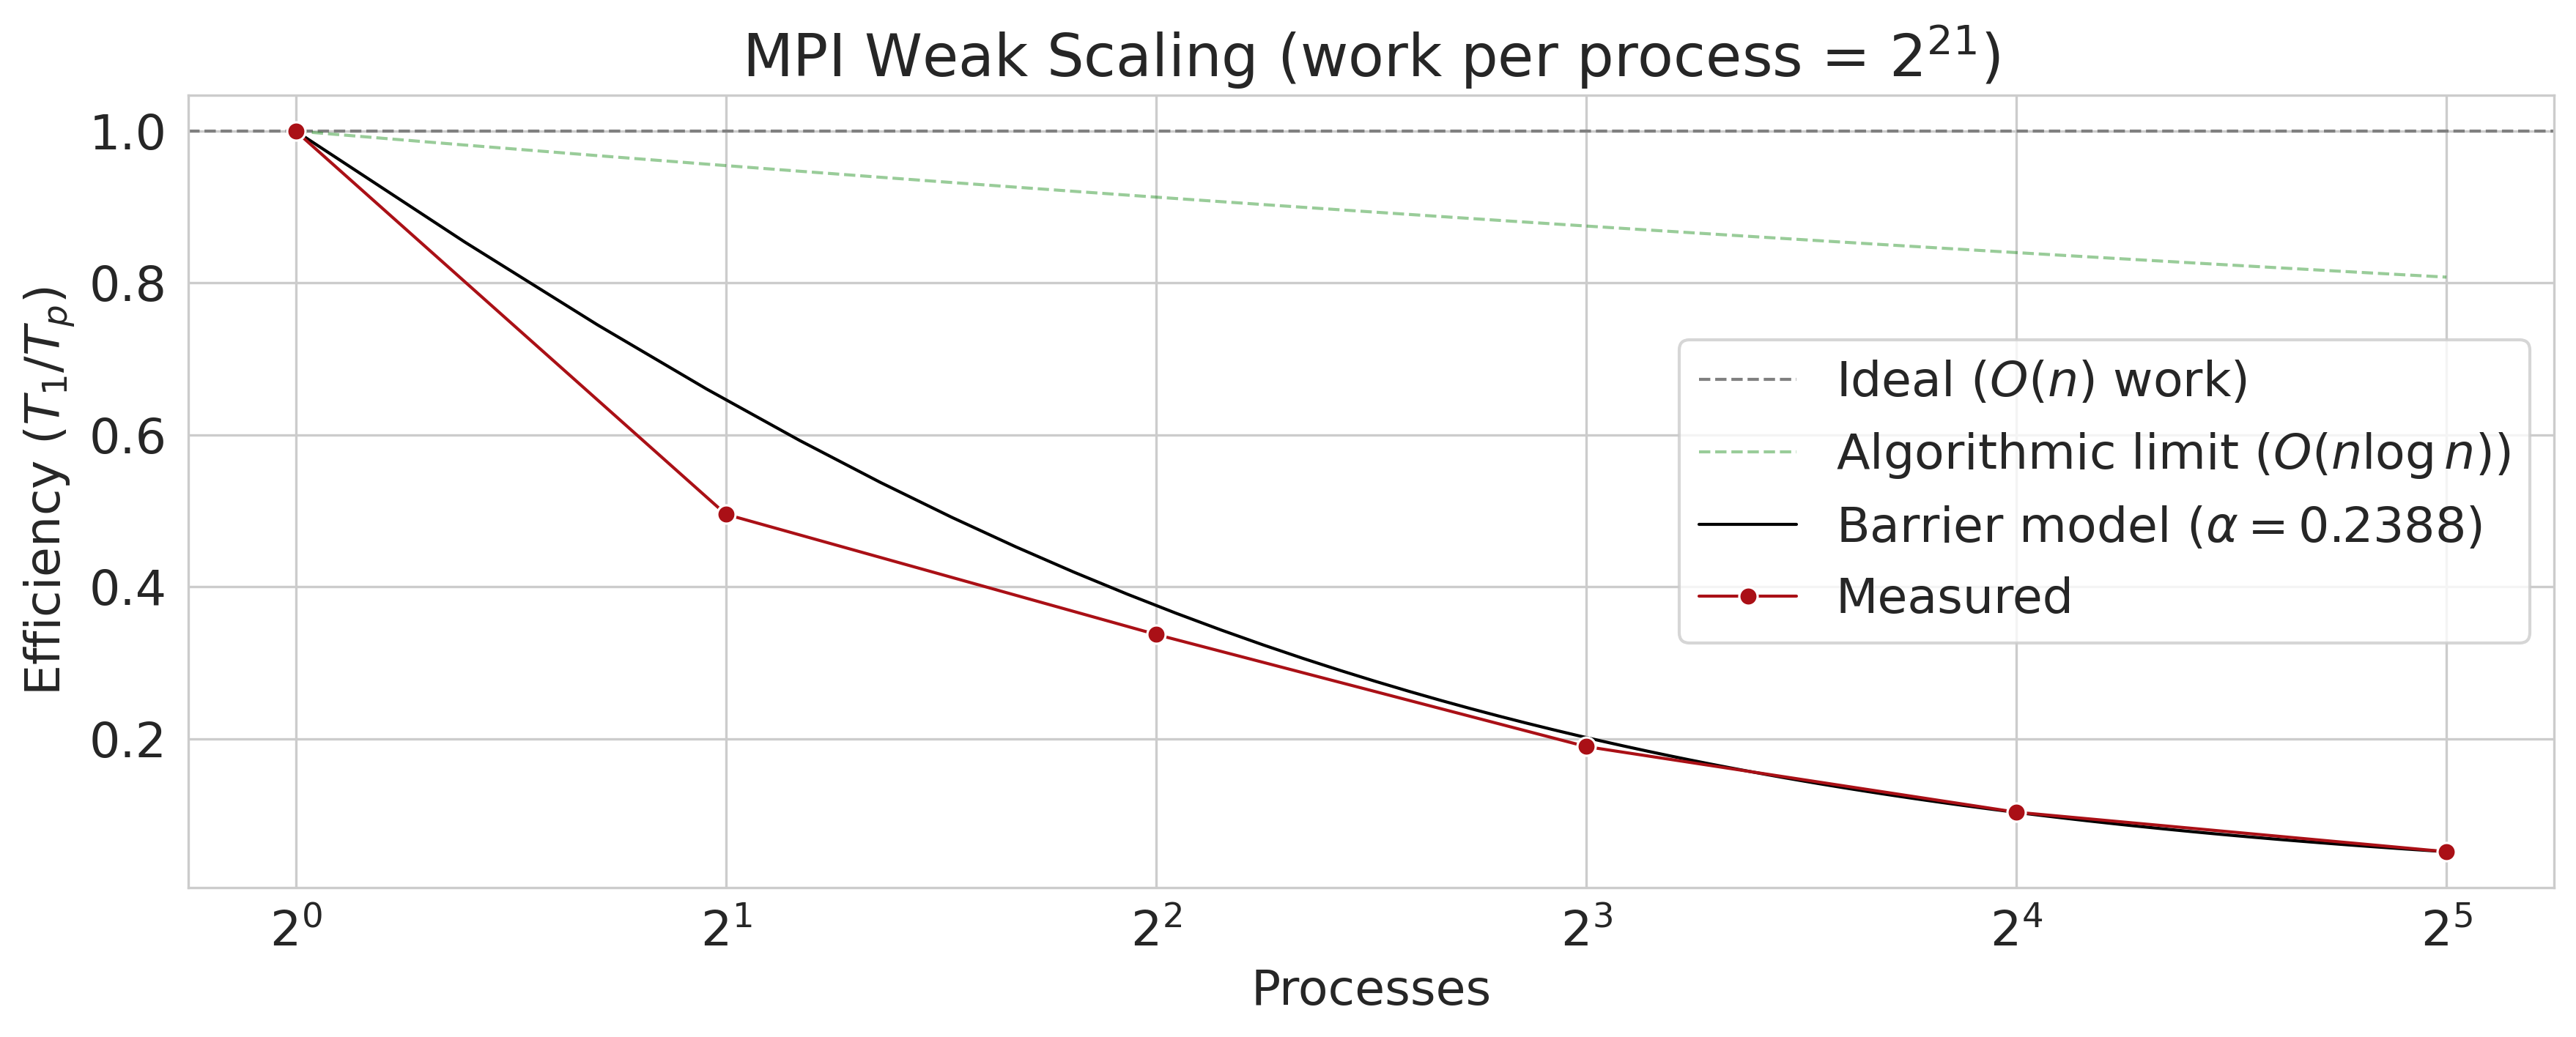

In [65]:
n_per_proc = int(n_to_compare / max(processes))
L = int(np.log2(n_per_proc))
baseline = mpi_df[(mpi_df["processes"] == 1) & (mpi_df["n"] == n_per_proc)][
    "time_ms"
].values[0]

efficiency = [
    baseline
    / mpi_df[(mpi_df["processes"] == p) & (mpi_df["n"] == p * n_per_proc)][
        "time_ms"
    ].values[0]
    for p in processes
]

# Algorithmic limit: E = L / (L + log2(p))
p_smooth = np.linspace(1, max(processes), 100)
algorithmic = L / (L + np.log2(p_smooth))

# Barrier model: E(p) = L / [(L + log2(p)) * (1 + 2(p-1) * alpha)]
p_max = processes[-1]
E_max = efficiency[-1]
alpha_weak_mpi = (L / (E_max * (L + np.log2(p_max))) - 1) / (2 * (p_max - 1))
barrier_model = L / (
    (L + np.log2(p_smooth)) * (1 + 2 * (p_smooth - 1) * alpha_weak_mpi)
)

plt.axhline(y=1, linestyle="--", color="gray", label="Ideal ($O(n)$ work)")
plt.plot(
    p_smooth,
    algorithmic,
    linestyle="--",
    color="green",
    alpha=0.4,
    label=f"Algorithmic limit ($O(n \\log n)$)",
)
plt.plot(
    p_smooth,
    barrier_model,
    linestyle="-",
    color="black",
    label=f"Barrier model ($\\alpha={alpha_weak_mpi:.4f}$)",
)

sns.lineplot(
    x=processes, y=efficiency, marker="o", color=mpi_col[-1], label="Measured"
)

plt.xscale("log", base=2)
plt.xlabel("Processes")
plt.ylabel("Efficiency ($T_1 / T_p$)")
plt.title(f"MPI Weak Scaling (work per process = $2^{{{L}}}$)")
plt.legend()
plt.tight_layout()
plt.savefig("plots/mpi_weak.svg")
plt.show()

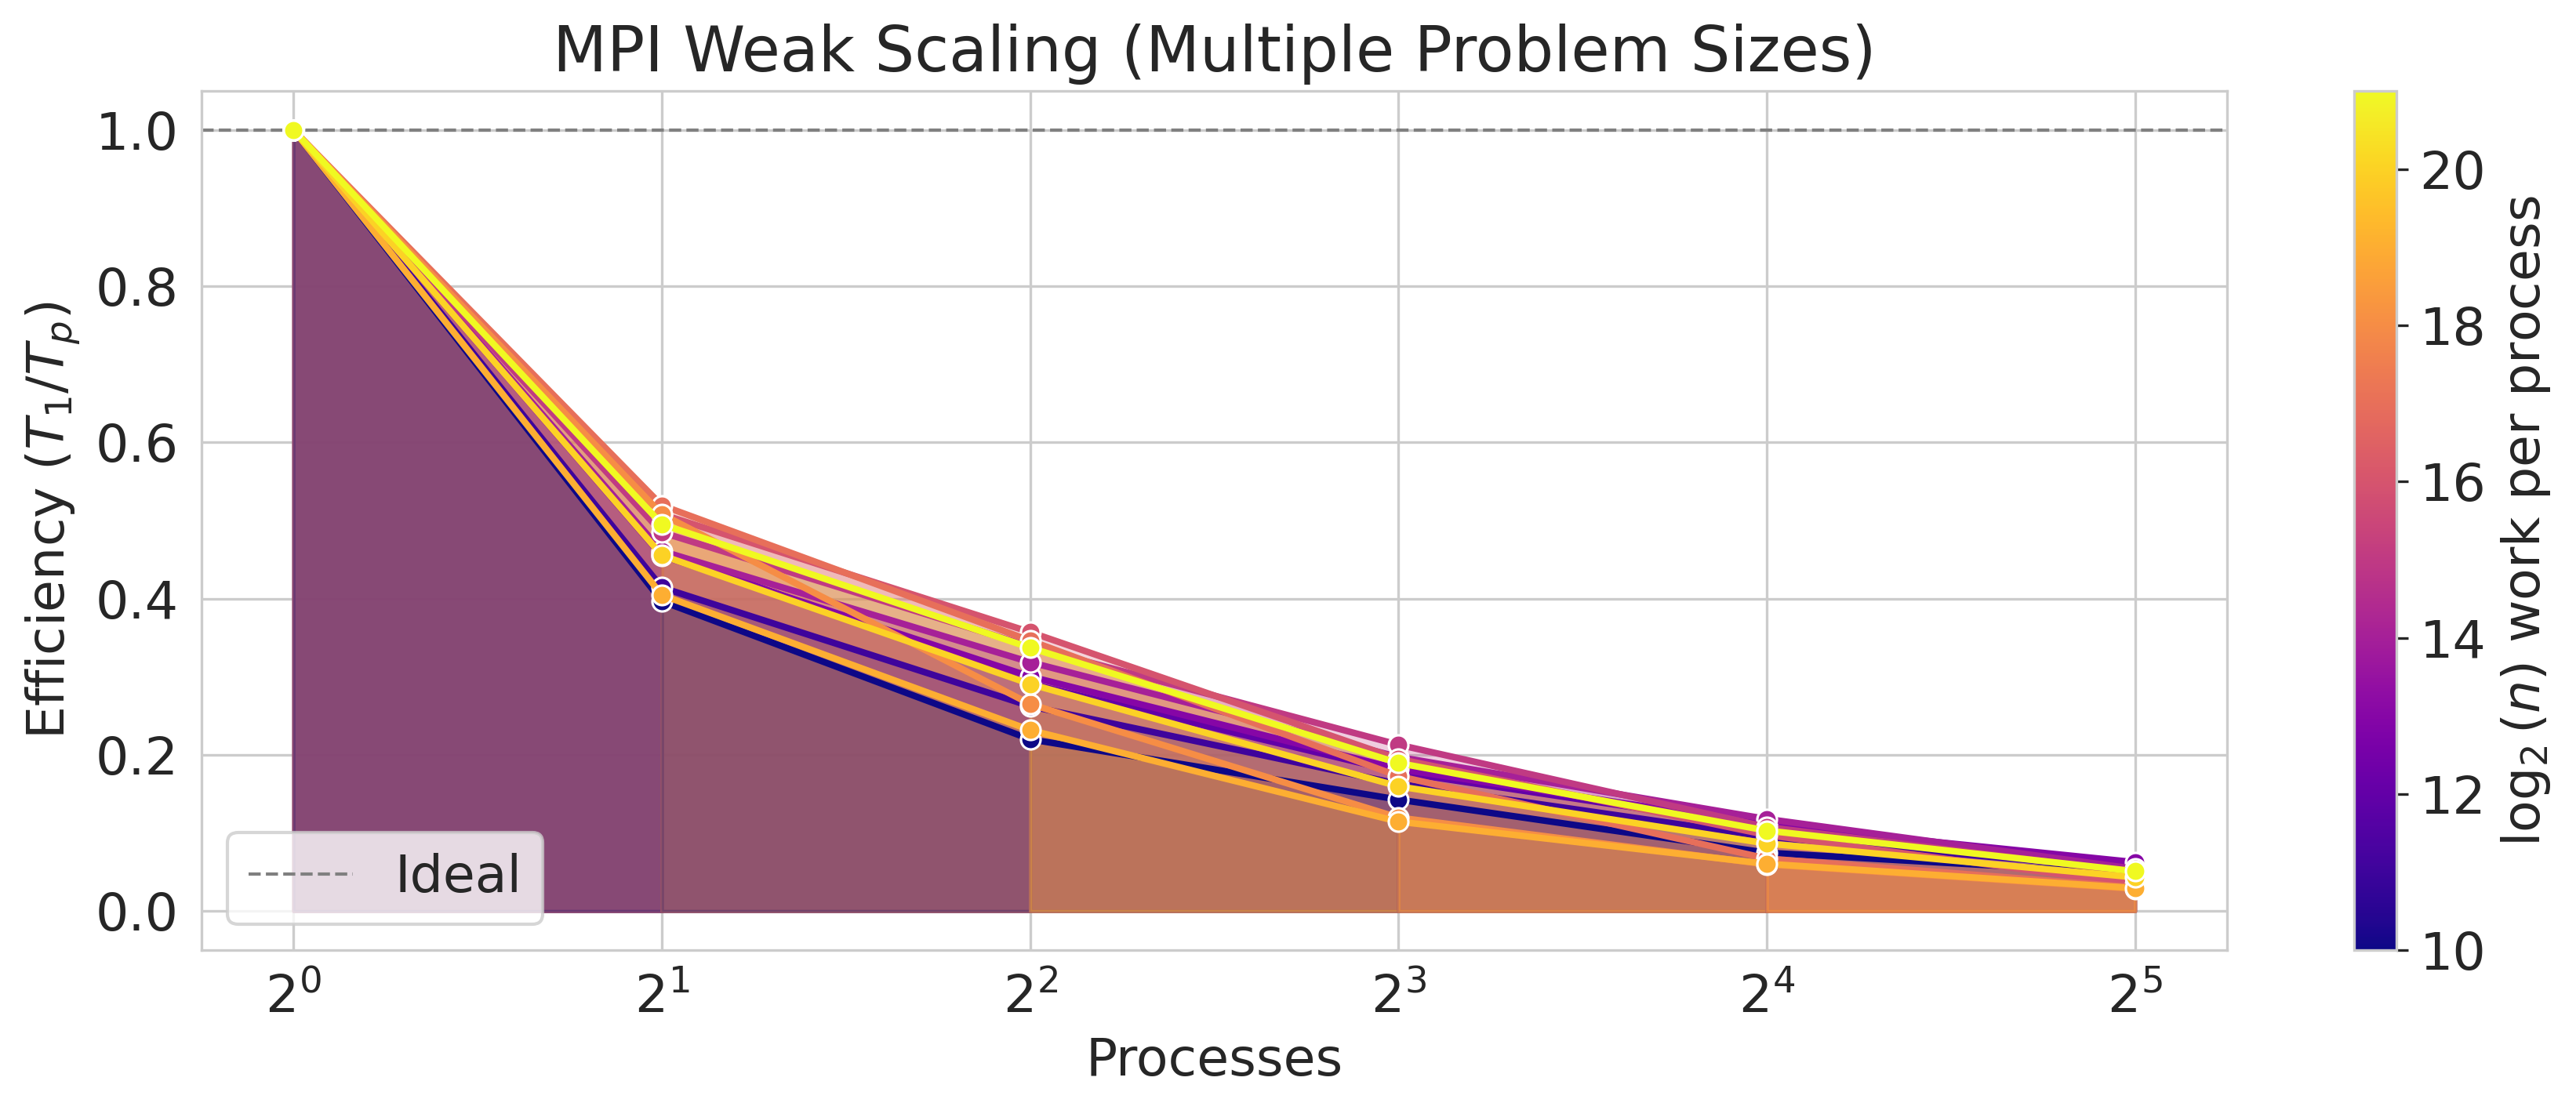

In [66]:
from plot_utils import (
    compute_multiscale_efficiency_series,
    draw_multiscale_series,
)

fig, ax = plt.subplots()
series, groups_all, max_group, norm, cmap = (
    compute_multiscale_efficiency_series(
        mpi_df,
        group_col="processes",
        n_col="n",
        time_col="time_ms",
        cmap=plt.cm.plasma,
    )
)
draw_multiscale_series(
    ax,
    series,
    groups_all,
    cmap,
    norm,
    fill_y0=0,
    xlabel="Processes",
    ylabel="Efficiency ($T_1 / T_p$)",
    title="MPI Weak Scaling (Multiple Problem Sizes)",
    cbar_label="$\\log_2(n)$ work per process",
    vline=1,
    savepath="plots/mpi_weak_multiscale.svg",
)

## Speedup vs Serial

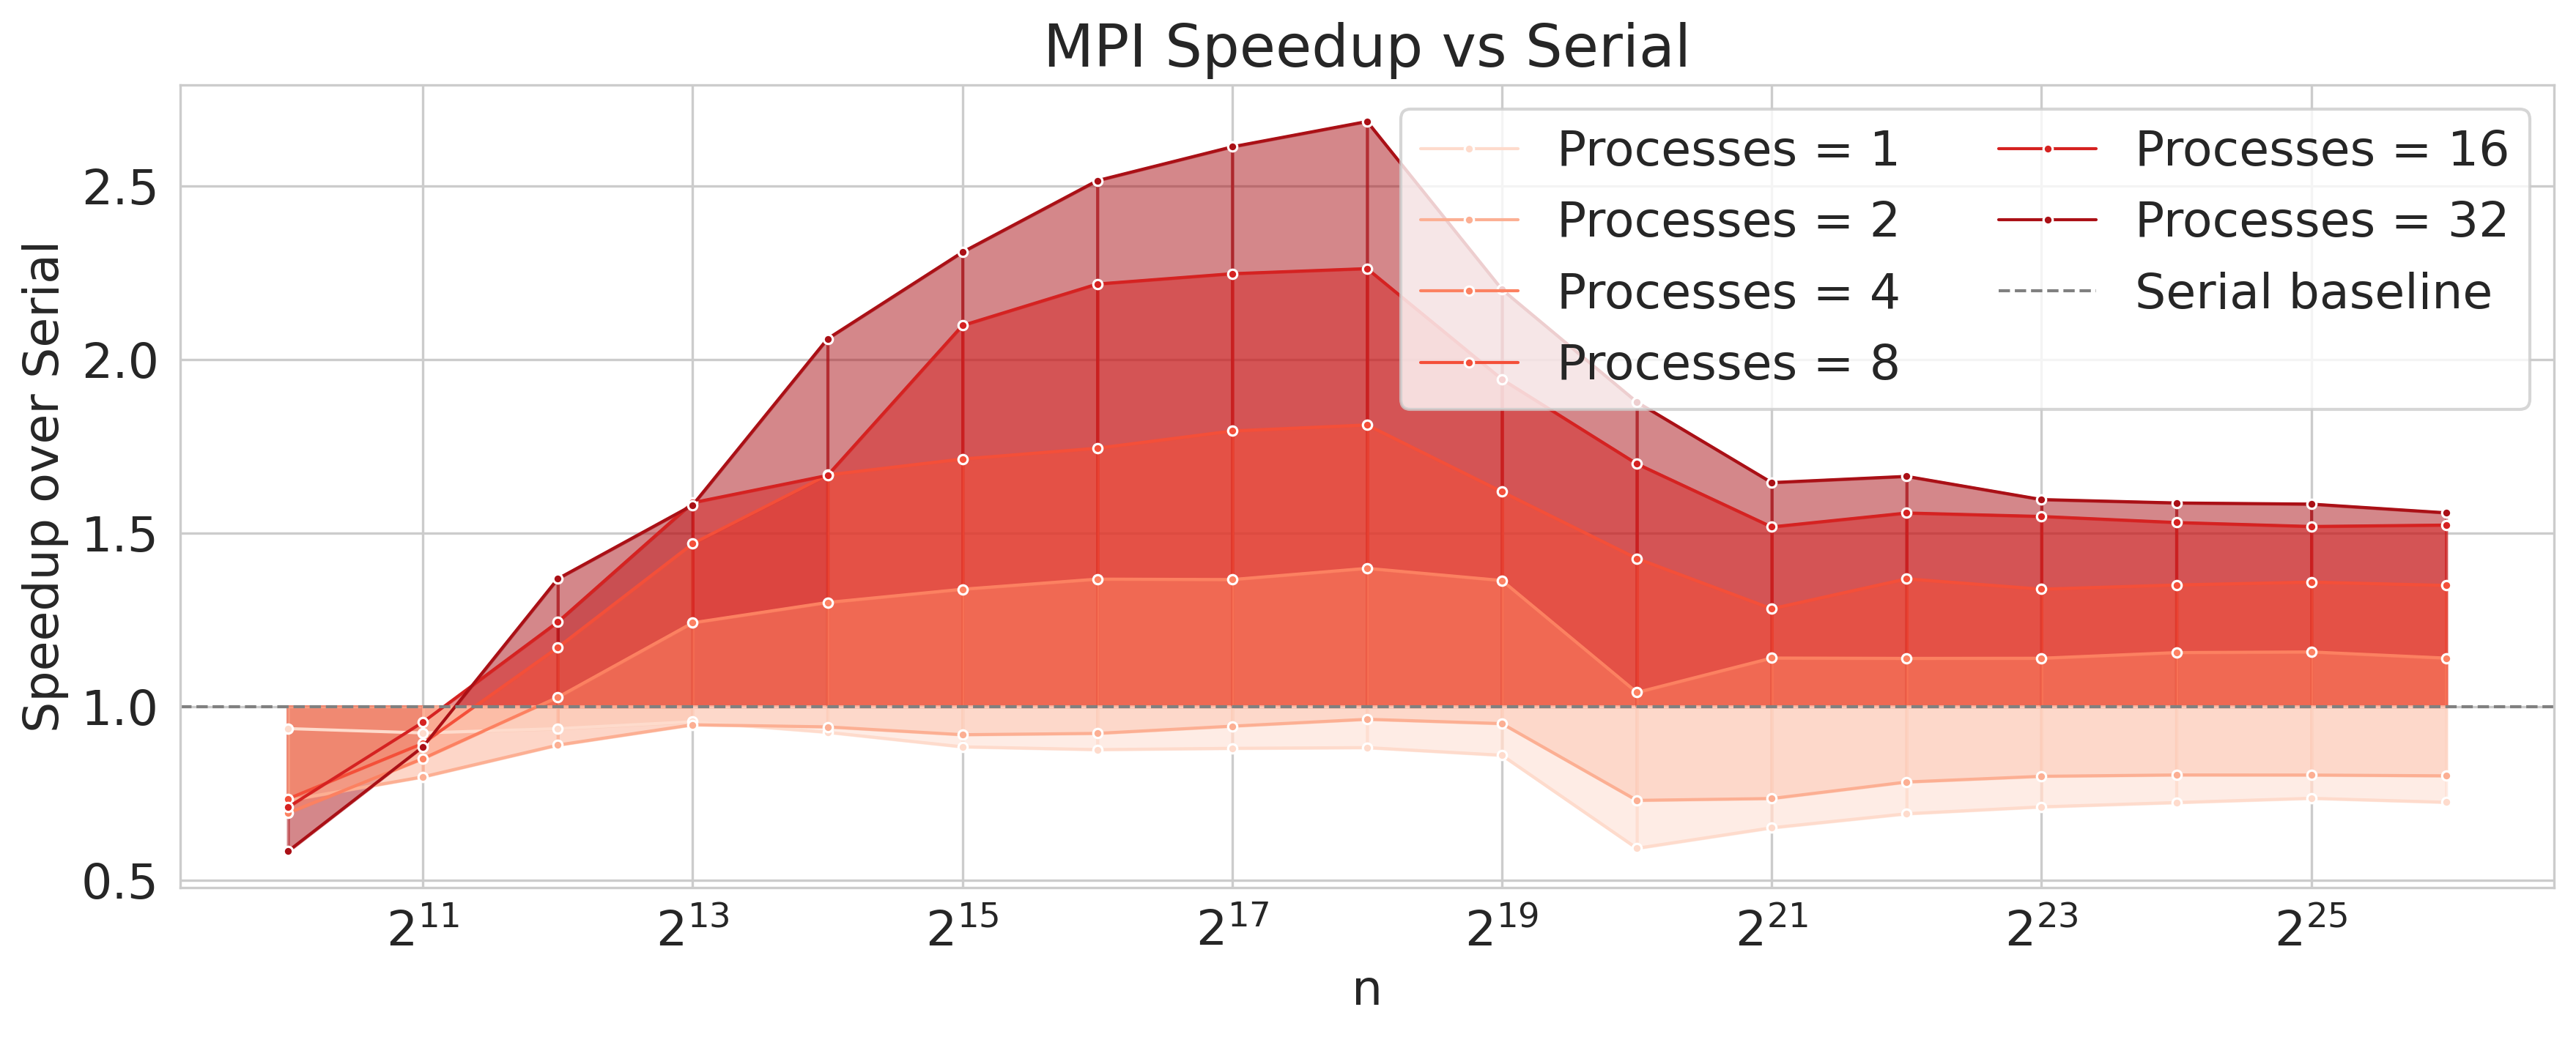

,processes,n,time_ms_impl,time_ms_serial,speedup
0,1,1024,0.016492,0.015444,0.936471
1,2,1024,0.021175,0.015444,0.729340
2,4,1024,0.022277,0.015444,0.693265
3,8,1024,0.021038,0.015444,0.734086
4,16,1024,0.021757,0.015444,0.709850
...,...,...,...,...,...
97,2,67108864,5404.540000,4325.570000,0.800359
98,4,67108864,3795.620000,4325.570000,1.139621
99,8,67108864,3206.450000,4325.570000,1.349022
100,16,67108864,2840.260000,4325.570000,1.522949


In [67]:
from plot_utils import plot_grouped_speedup_vs_serial

fig, ax = plt.subplots()
plot_grouped_speedup_vs_serial(
    ax,
    mpi_df,
    serial_df,
    group_col="processes",
    colors=mpi_col,
    marker="o",
    label_template="Processes = {value}",
    xlabel="n",
    ylabel="Speedup over Serial",
    title="MPI Speedup vs Serial",
    legend_kwargs={"ncol": 2},
    savepath="plots/mpi_speedup.svg",
)

# CUDA

## Speedup vs Serial

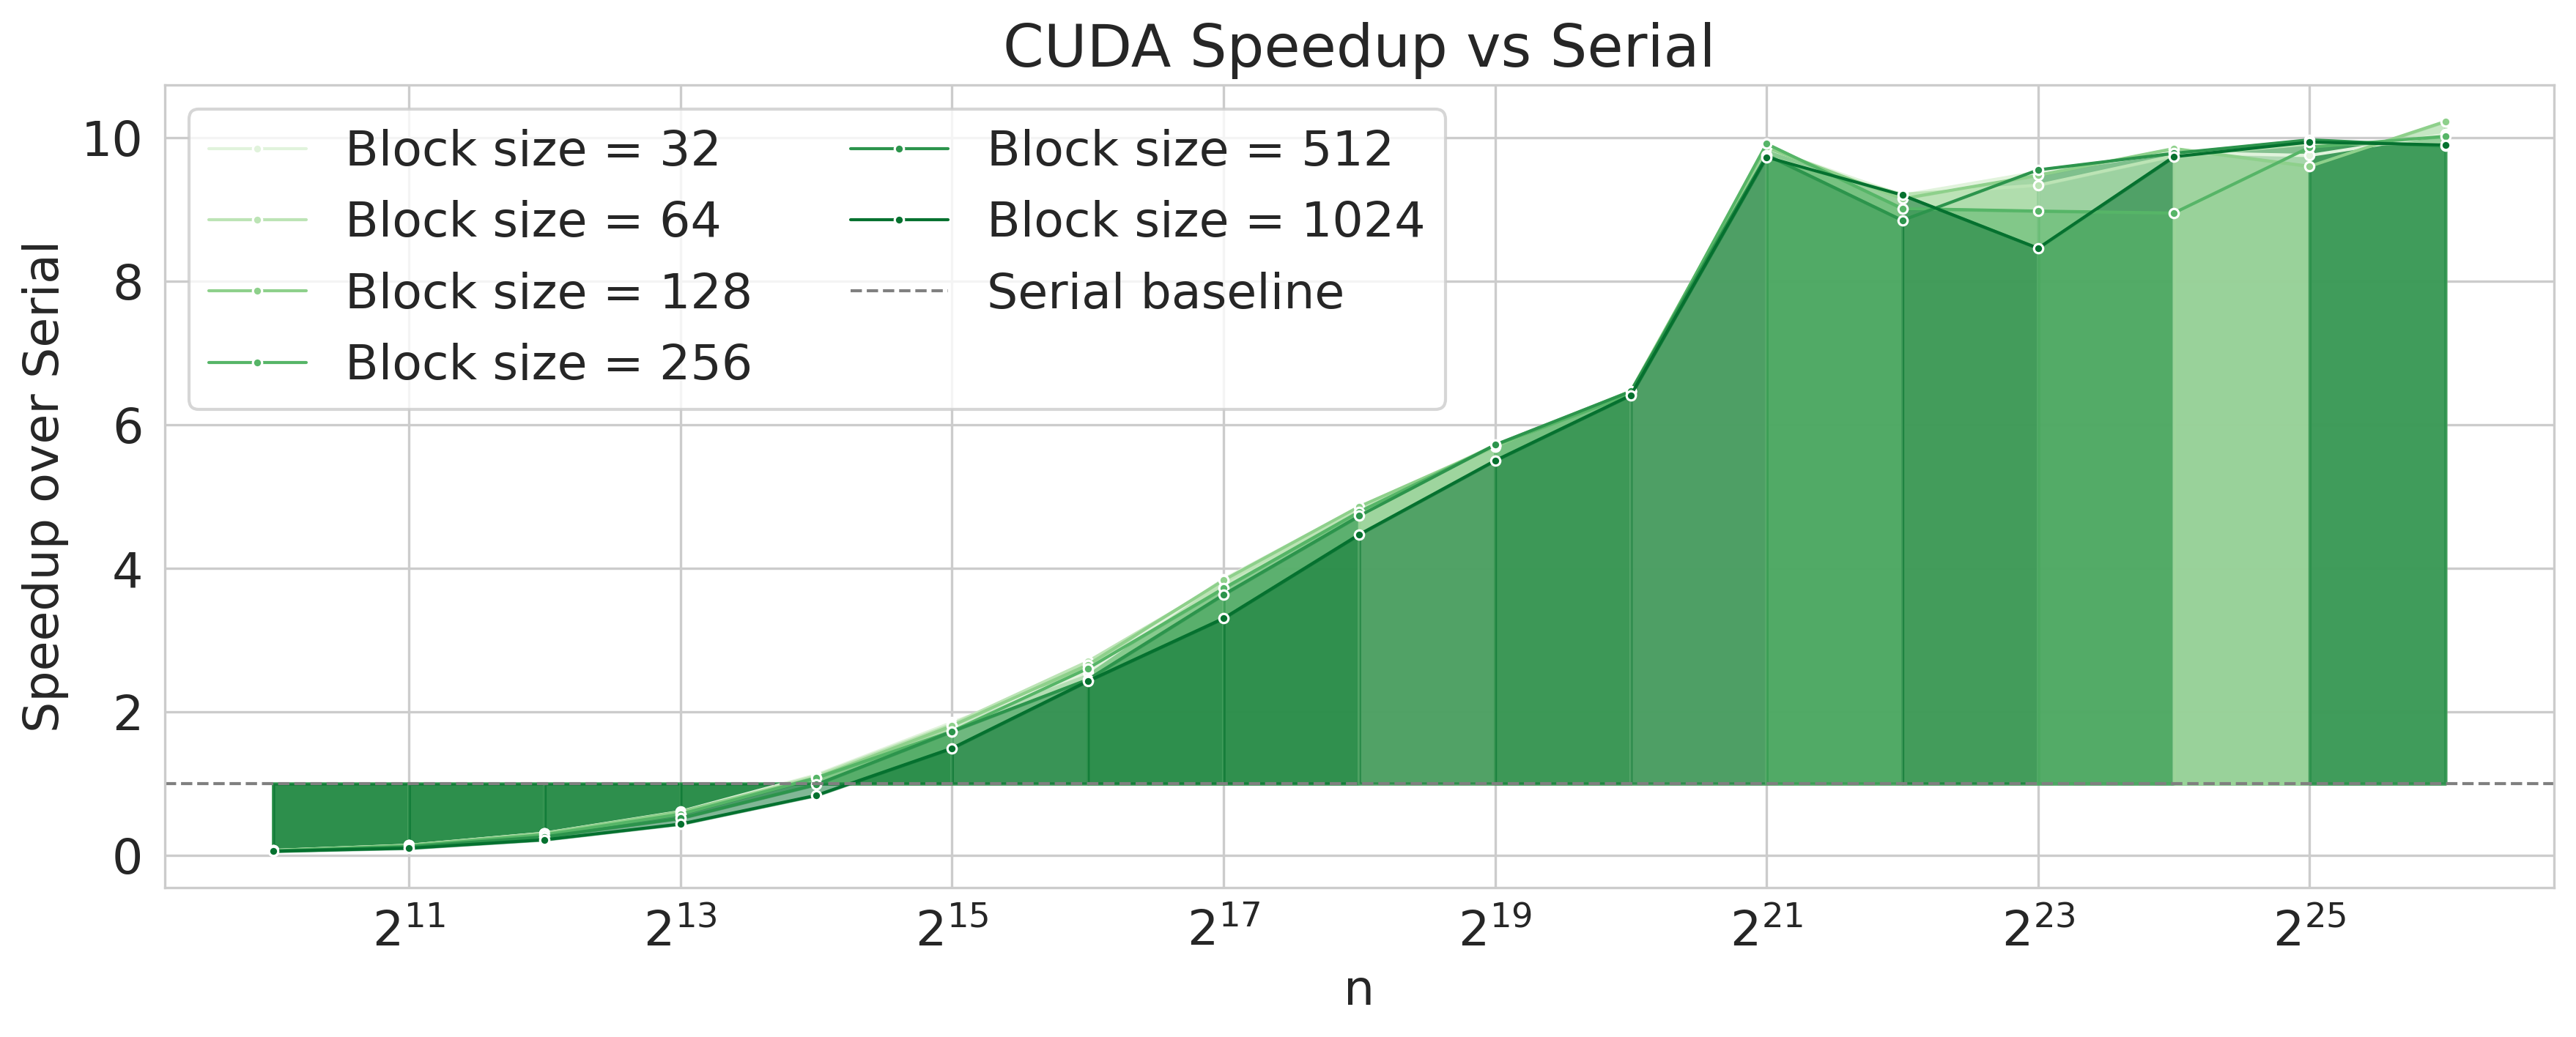

,block_size,n,time_ms_impl,time_ms_serial,speedup
0,32,1024,0.223114,0.015444,0.069220
1,64,1024,0.222150,0.015444,0.069521
2,128,1024,0.227329,0.015444,0.067937
3,256,1024,0.239893,0.015444,0.064379
4,512,1024,0.265543,0.015444,0.058160
...,...,...,...,...,...
97,64,67108864,436.505000,4325.570000,9.909554
98,128,67108864,422.966000,4325.570000,10.226756
99,256,67108864,431.704000,4325.570000,10.019759
100,512,67108864,437.668000,4325.570000,9.883222


In [68]:
from plot_utils import plot_grouped_speedup_vs_serial

fig, ax = plt.subplots()
plot_grouped_speedup_vs_serial(
    ax,
    cuda_df,
    serial_df,
    group_col="block_size",
    colors=cuda_col,
    marker="o",
    label_template="Block size = {value}",
    xlabel="n",
    ylabel="Speedup over Serial",
    title="CUDA Speedup vs Serial",
    legend_kwargs={"ncol": 2},
    savepath="plots/cuda_speedup.svg",
)

## Speedup vs Serial (by block size)

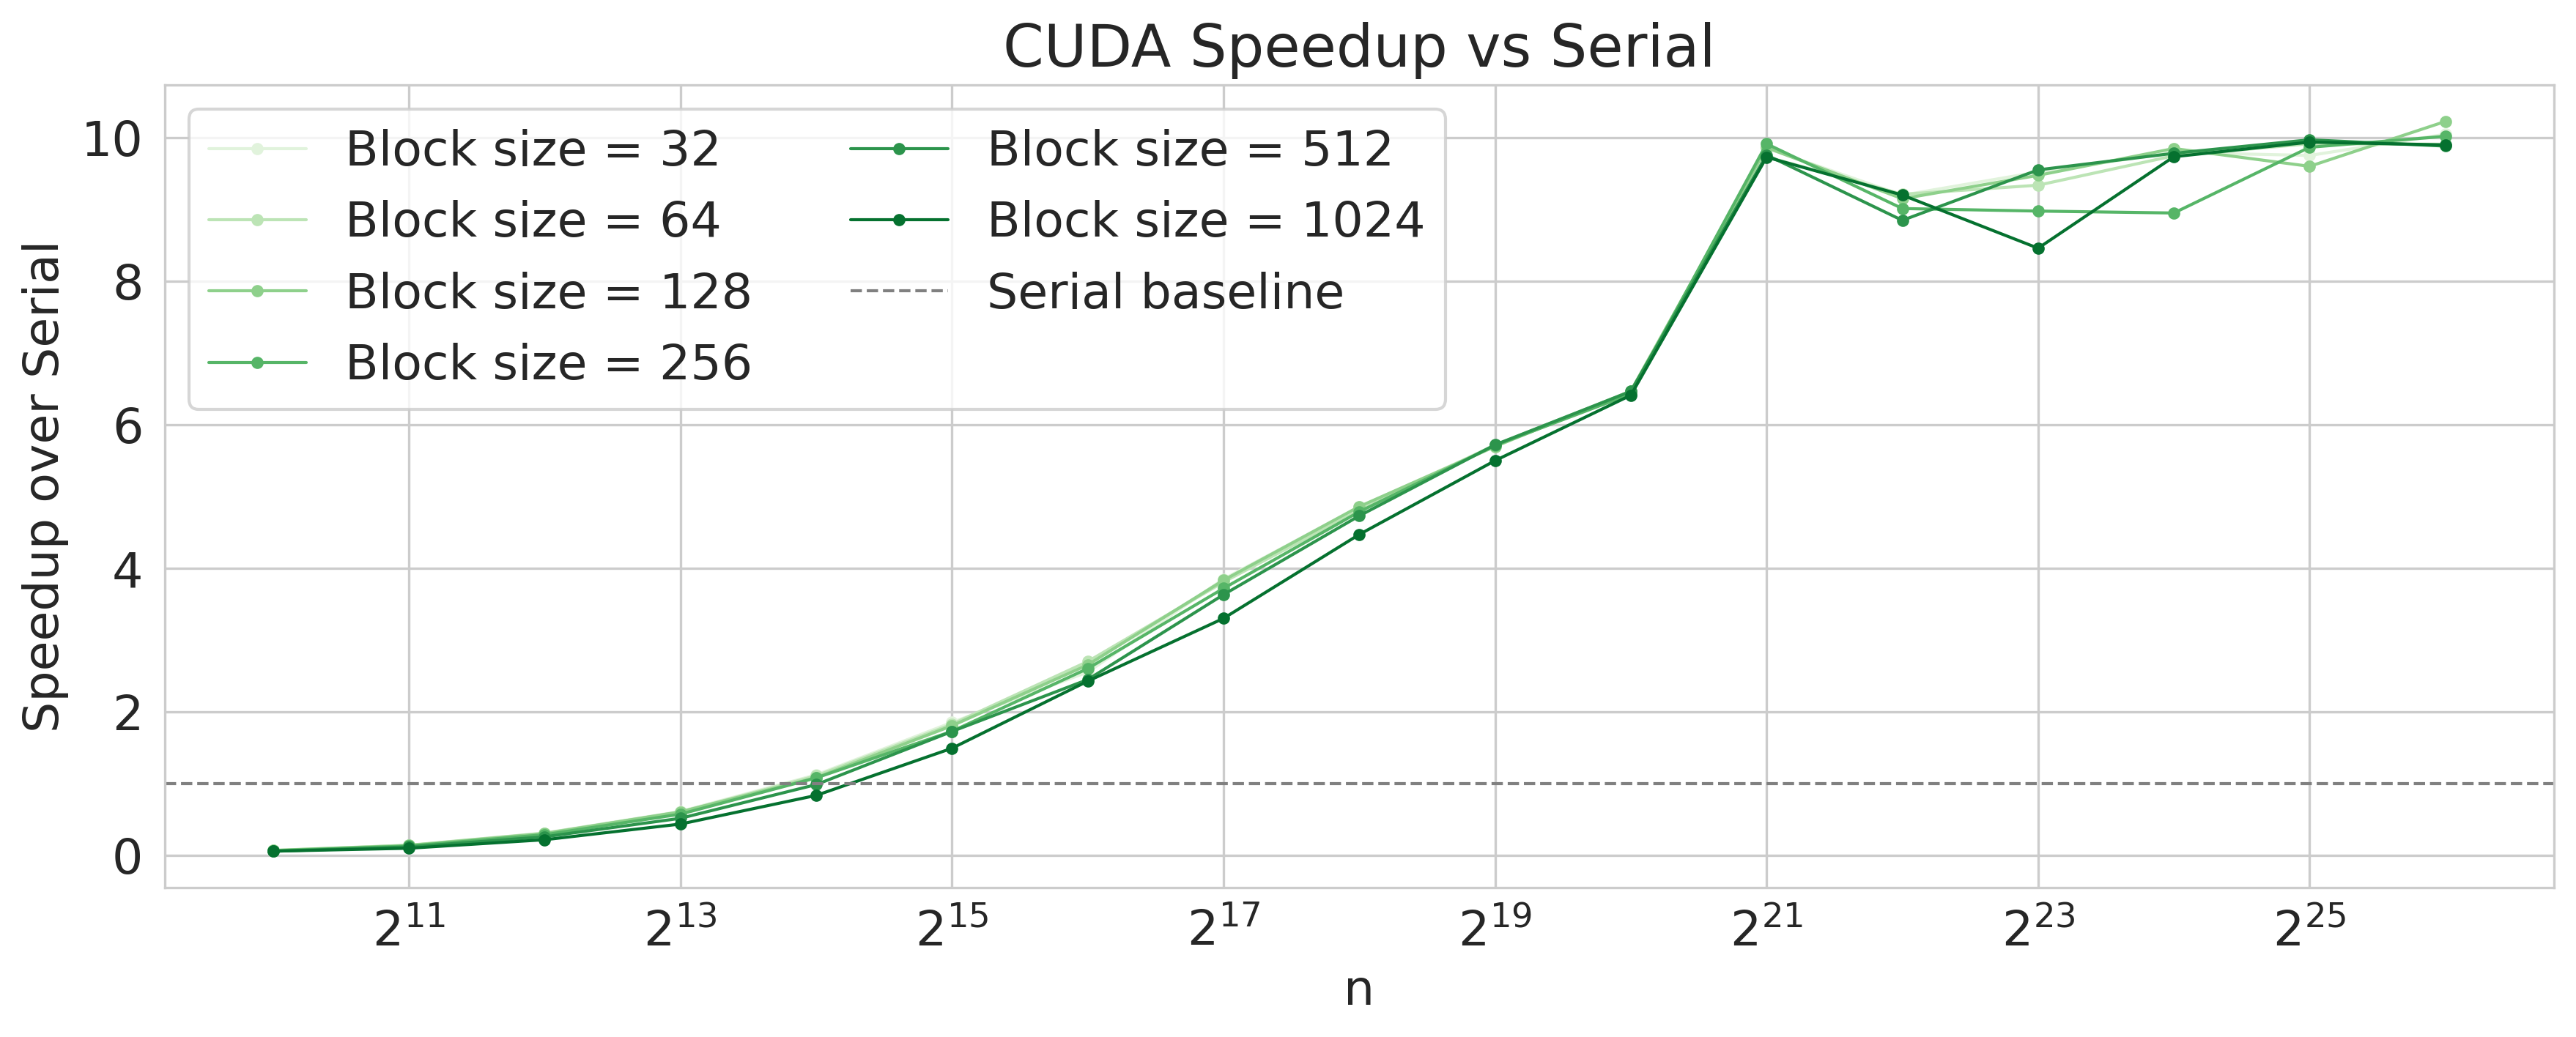

In [69]:
cuda_merged = cuda_df.merge(serial_df, on="n", suffixes=("_cuda", "_serial"))
cuda_merged["speedup"] = cuda_merged["time_ms_serial"] / cuda_merged["time_ms_cuda"]

block_sizes = sorted(cuda_df["block_size"].unique())
for i, bs in enumerate(block_sizes):
    subset = cuda_merged[cuda_merged["block_size"] == bs]
    plt.plot(subset["n"], subset["speedup"], marker='o', markersize=3, color=cuda_col[i], label=f"Block size = {bs}")

plt.axhline(y=1, linestyle='--', color='gray', label='Serial baseline')
plt.xscale("log", base=2)
plt.xlabel("n")
plt.ylabel("Speedup over Serial")
plt.title("CUDA Speedup vs Serial")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig("plots/cuda_speedup.svg")
plt.show()

## Strong scaling (multiple block sizes and problem sizes)

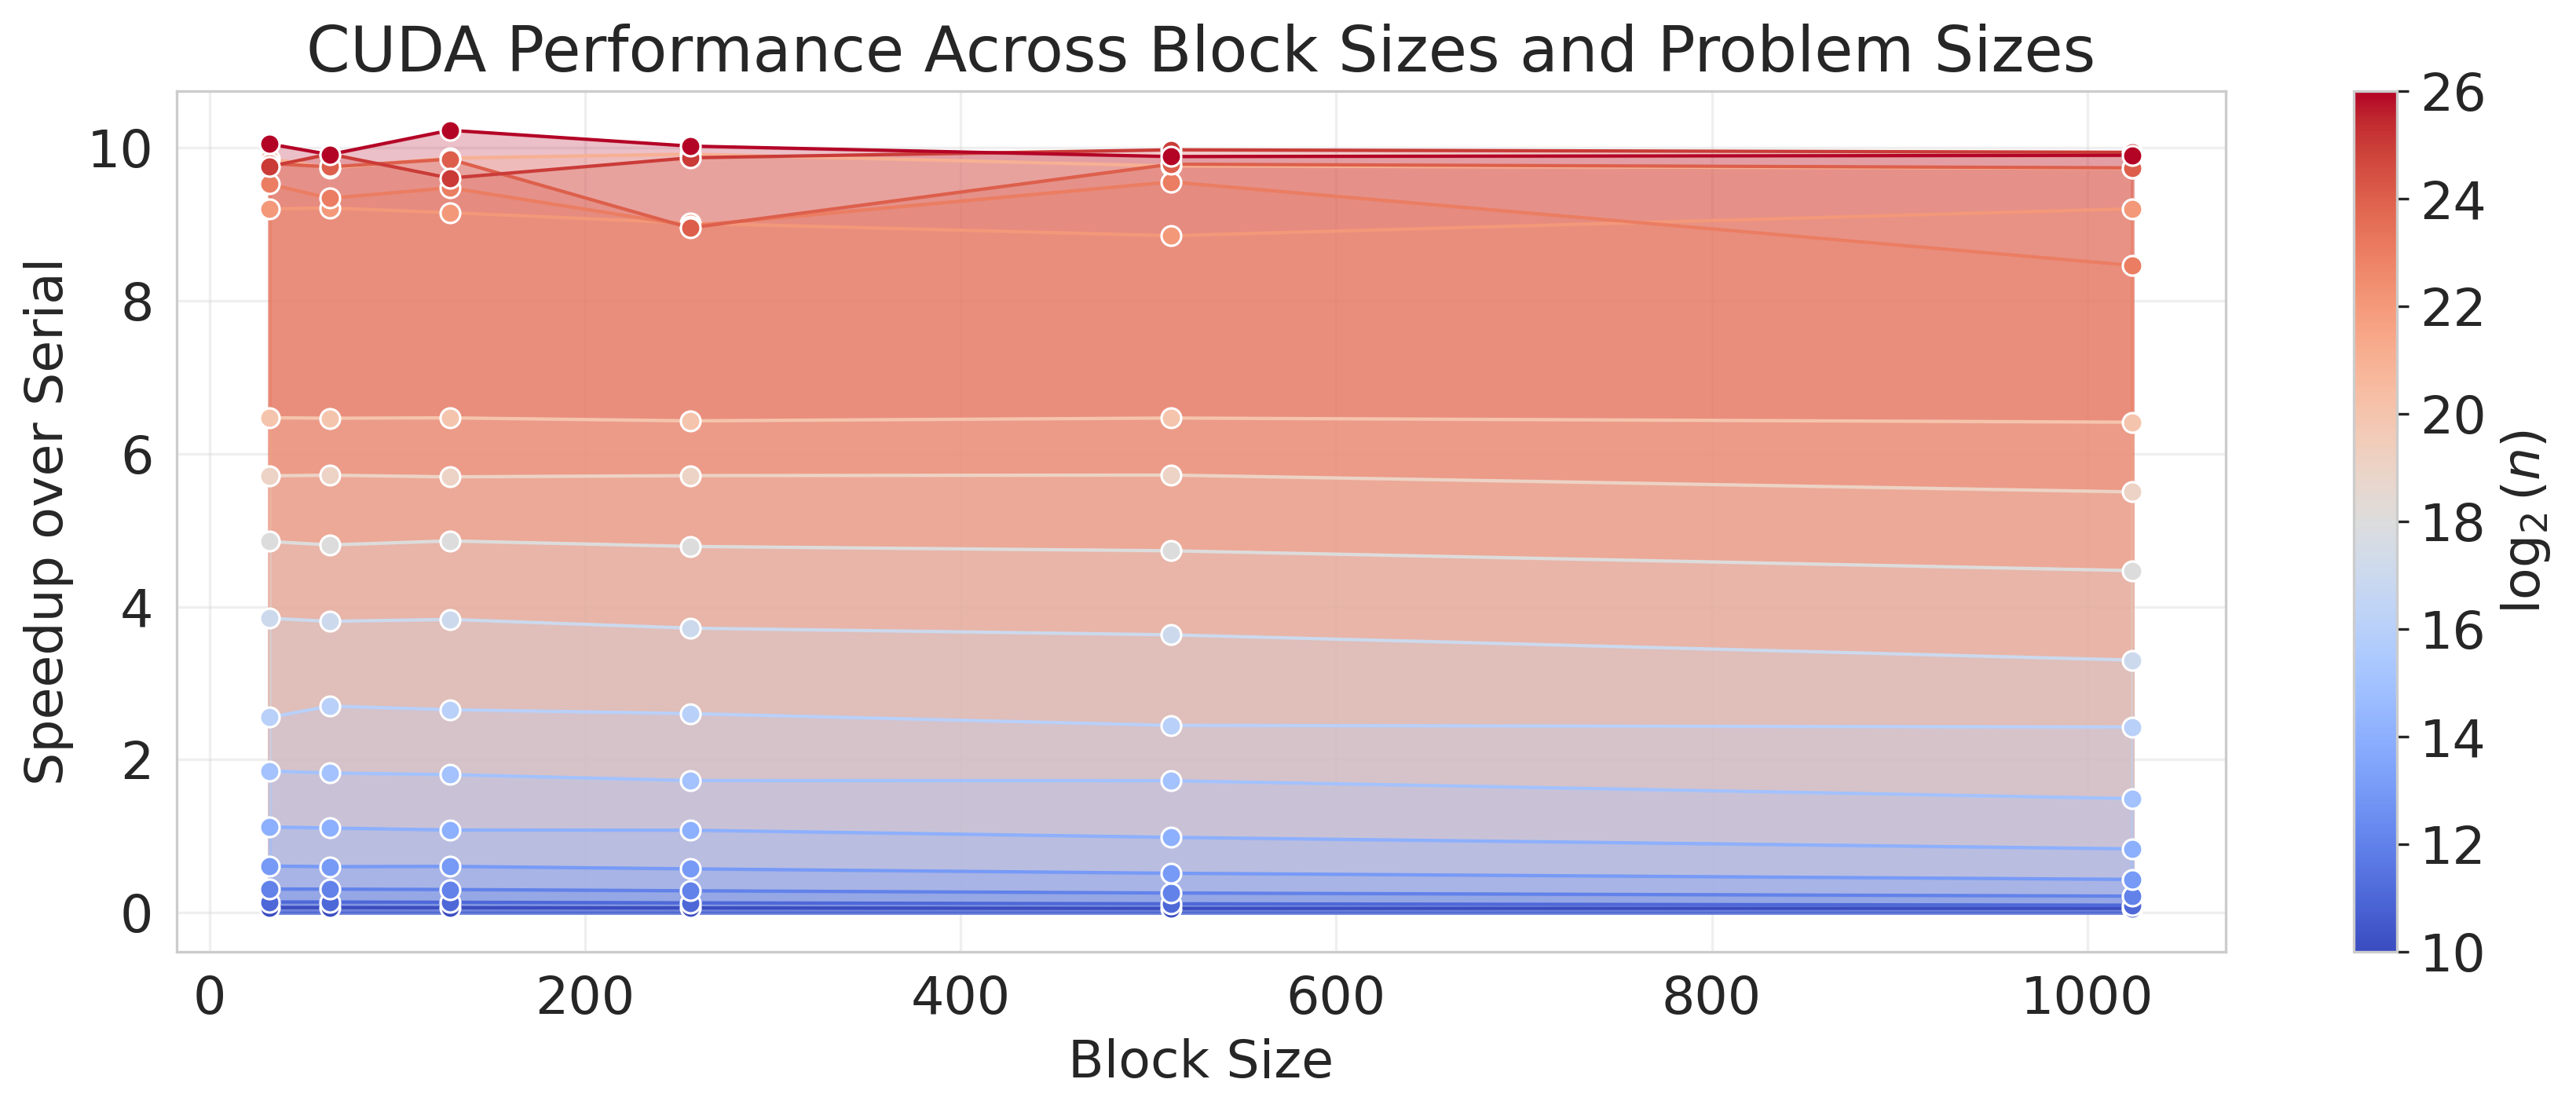

In [70]:
def compute_cuda_block_series(
    cuda_df,
    serial_df,
    block_col="block_size",
    n_col="n",
    time_col="time_ms",
    cmap=None,
):
    block_sizes = np.array(sorted(cuda_df[block_col].unique()))
    n_values = sorted(cuda_df[n_col].unique())
    norm = plt.Normalize(vmin=np.log2(n_values[0]), vmax=np.log2(n_values[-1]))
    cmap = cmap or plt.cm.coolwarm
    series = []
    for n_to_compare in n_values:
        serial_time = serial_df[serial_df[n_col] == n_to_compare][
            time_col
        ].values[0]
        block_speedups = []
        for bs in block_sizes:
            subset = cuda_df[
                (cuda_df[n_col] == n_to_compare) & (cuda_df[block_col] == bs)
            ]
            if len(subset) > 0:
                block_speedups.append(serial_time / subset[time_col].values[0])
            else:
                block_speedups.append(np.nan)
        color = cmap(norm(np.log2(n_to_compare)))
        series.append(
            (block_sizes, np.array(block_speedups, dtype=float), color)
        )
    return series, block_sizes, norm, cmap


def draw_cuda_series(
    ax,
    series,
    block_sizes,
    cmap,
    norm,
    xlabel="Block Size",
    ylabel="Speedup over Serial",
    title="",
    savepath=None,
):
    # Draw filled area and lines handling NaNs
    for xvals, yvals, color in sorted(
        series, key=lambda s: np.nanmax(s[1]), reverse=True
    ):
        valid = ~np.isnan(yvals)
        if valid.any():
            ax.fill_between(
                xvals[valid], 0, yvals[valid], color=color, alpha=0.25
            )

    for xvals, yvals, color in series:
        sns.lineplot(ax=ax, x=xvals, y=yvals, marker="o", color=color)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label("$\\log_2(n)$")

    if savepath:
        plt.tight_layout()
        plt.savefig(savepath)
    plt.show()


fig, ax = plt.subplots()
series, block_sizes, norm, cmap = compute_cuda_block_series(
    cuda_df, serial_df, block_col="block_size", n_col="n", time_col="time_ms"
)
draw_cuda_series(
    ax,
    series,
    block_sizes,
    cmap,
    norm,
    xlabel="Block Size",
    ylabel="Speedup over Serial",
    title="CUDA Performance Across Block Sizes and Problem Sizes",
    savepath="plots/cuda_strong_multiscale.svg",
)

# JAX

## Speedup vs Serial

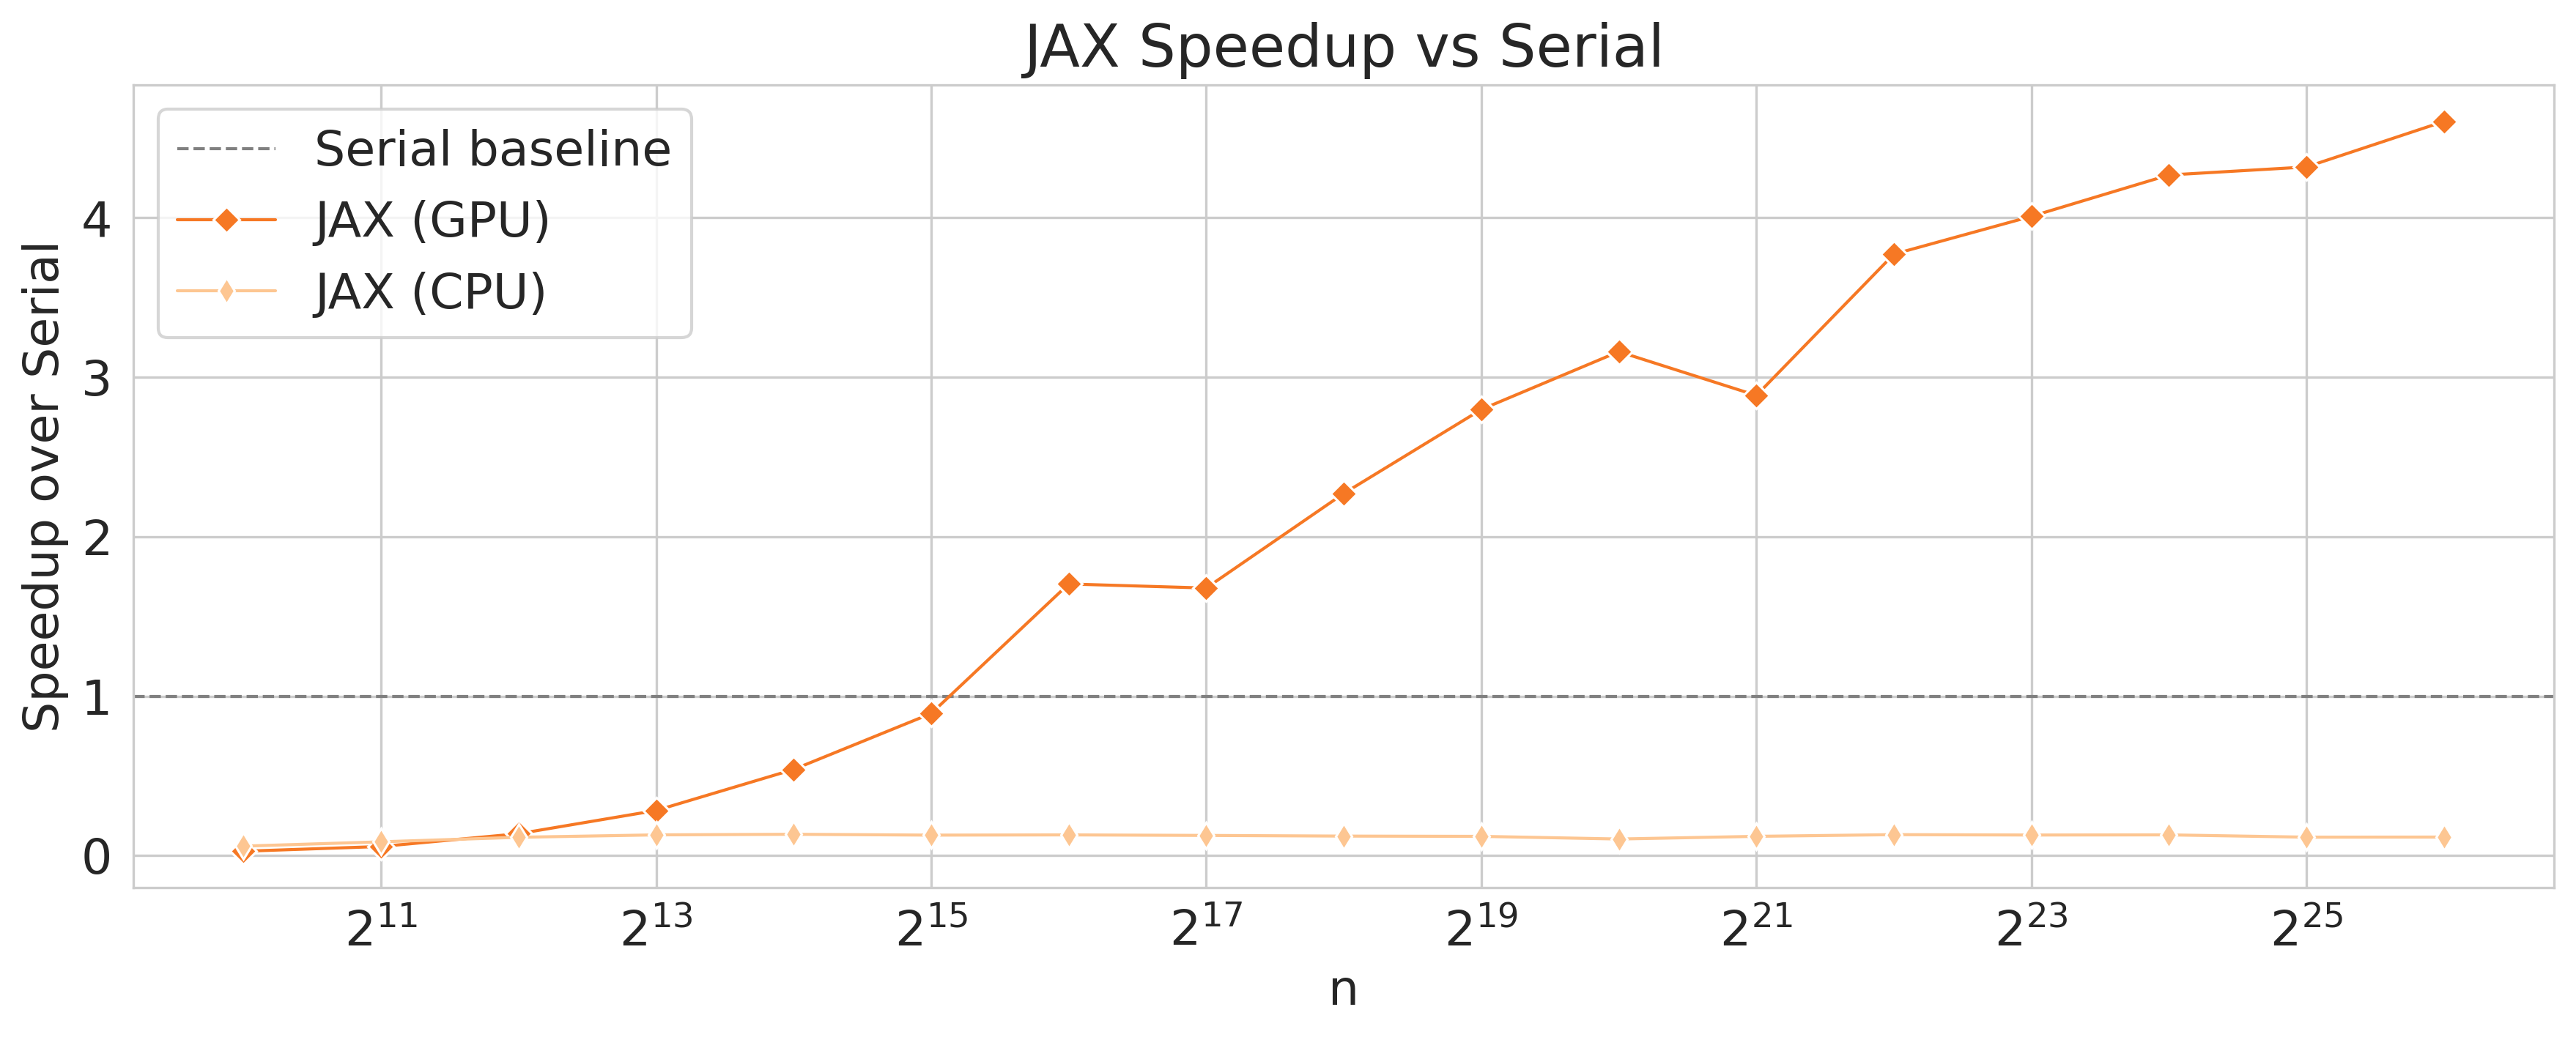

In [71]:
from plot_utils import merge_speedup_frame, plot_grouped_lines

jax_gpu_merged = merge_speedup_frame(jax_gpu_df, serial_df, key="n", time_col="time_ms", frame_suffix="jax")
jax_cpu_merged = merge_speedup_frame(jax_cpu_df, serial_df, key="n", time_col="time_ms", frame_suffix="jax")

fig, ax = plt.subplots()
plot_grouped_lines(
    ax,
    [
        (jax_gpu_merged, addn_col[3], "D", "JAX (GPU)", None),
        (jax_cpu_merged, addn_col[1], "d", "JAX (CPU)", None),
    ],
    x_col="n",
    y_col="speedup",
    baseline_y=1,
    baseline_label="Serial baseline",
    xlabel="n",
    ylabel="Speedup over Serial",
    title="JAX Speedup vs Serial",
    savepath="plots/jax_speedup.svg",
)

# Combined Comparison

## Best of each implementation (runtime vs n)

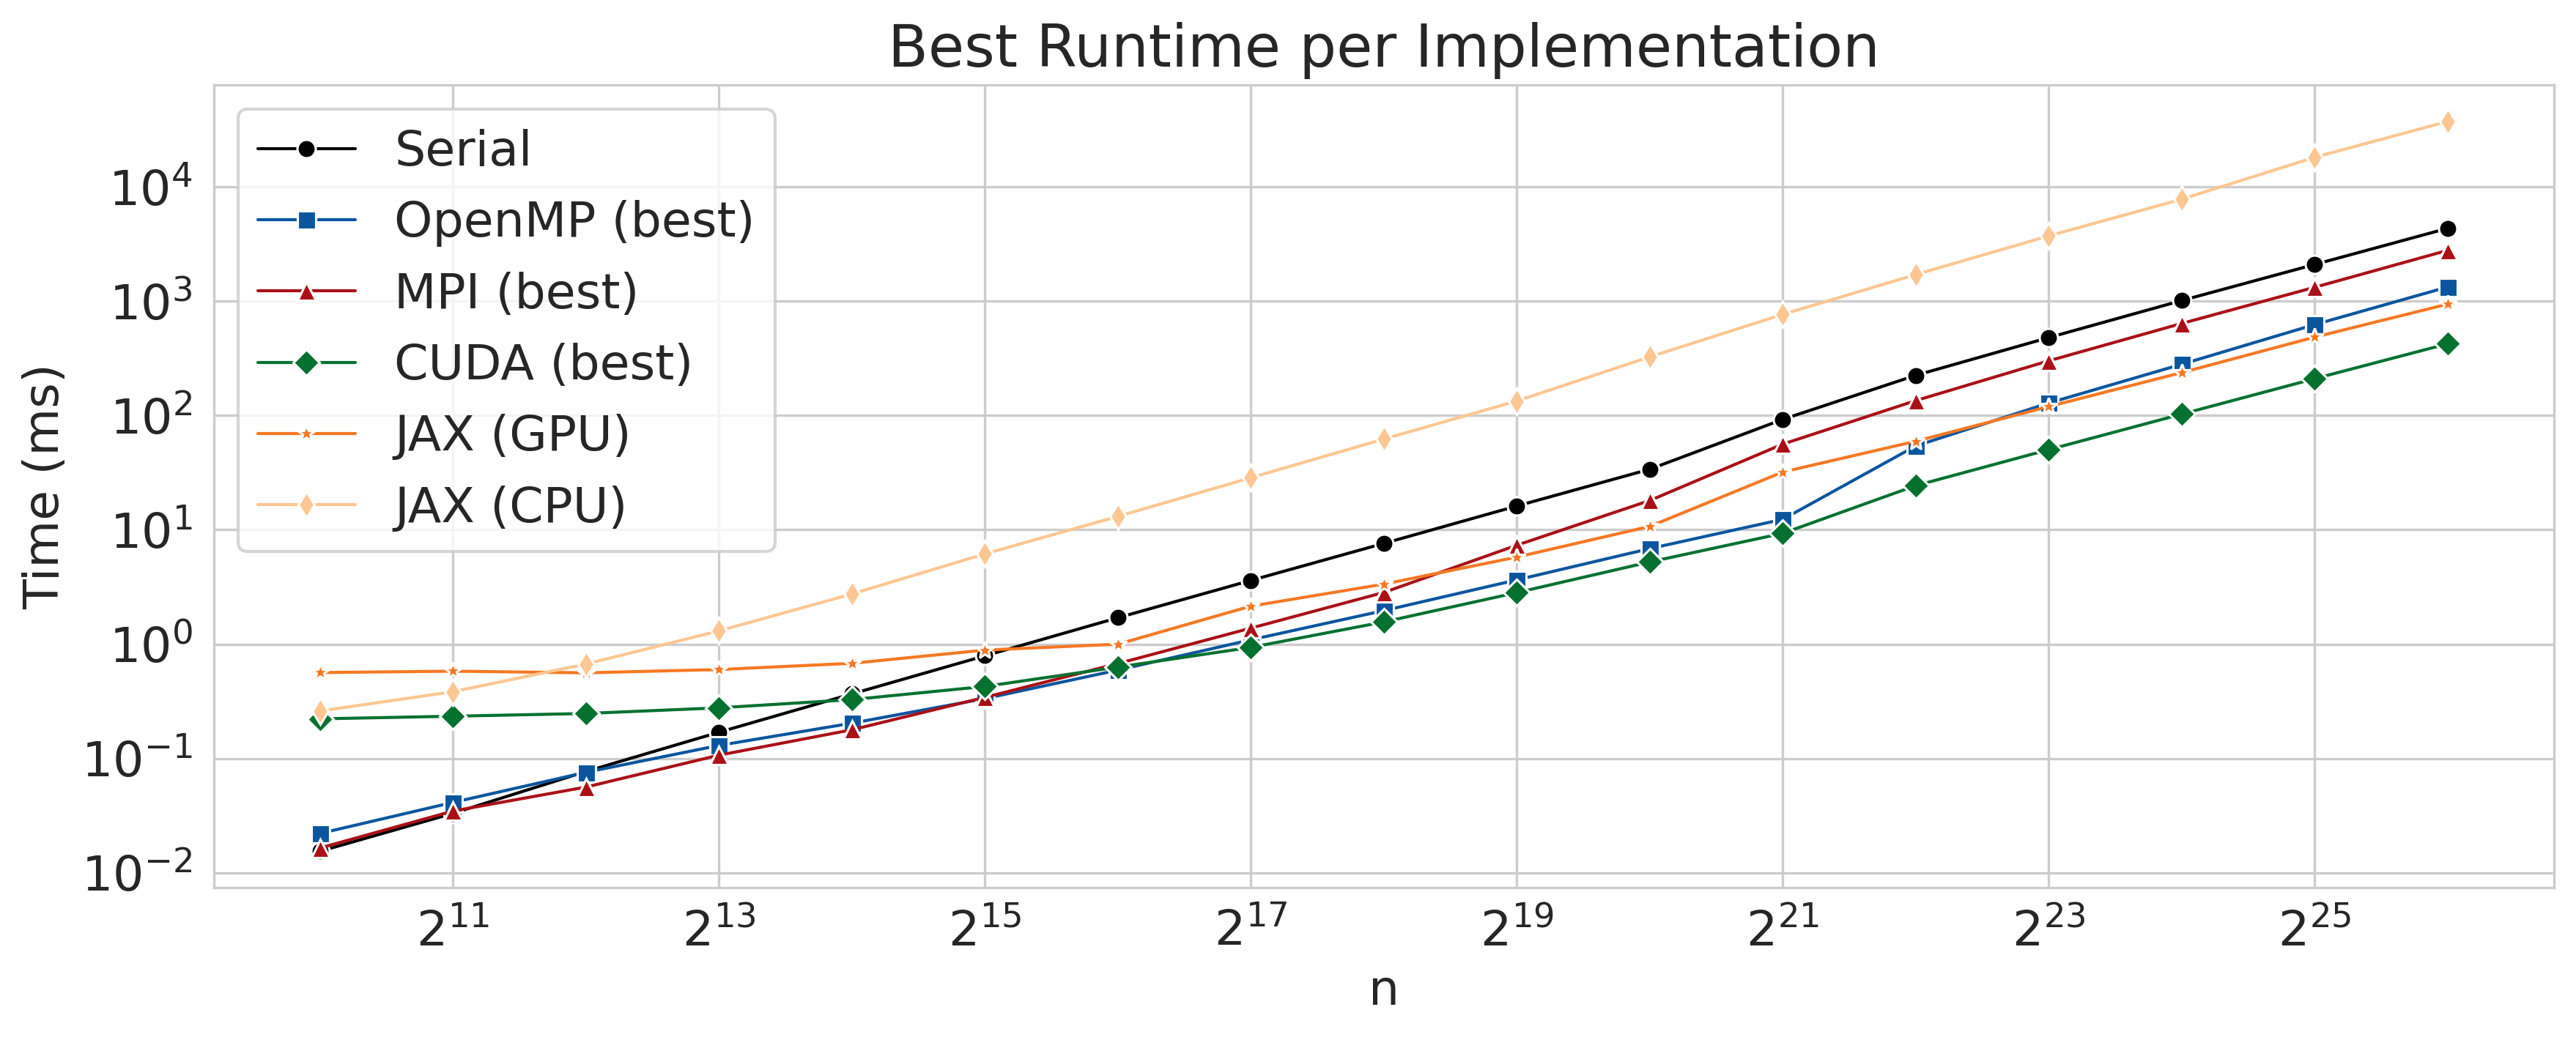

In [72]:
from plot_utils import plot_grouped_lines

# best config for each implementation
omp_best = omp_df.loc[omp_df.groupby("n")["time_ms"].idxmin()].reset_index(drop=True)
mpi_best = mpi_df.loc[mpi_df.groupby("n")["time_ms"].idxmin()].reset_index(drop=True)
cuda_best = cuda_df.loc[cuda_df.groupby("n")["time_ms"].idxmin()].reset_index(drop=True)

fig, ax = plt.subplots()
plot_grouped_lines(
    ax,
    [
        (serial_df, serial_col, "o", "Serial", None),
        (omp_best, omp_col[-1], "s", "OpenMP (best)", None),
        (mpi_best, mpi_col[-1], "^", "MPI (best)", None),
        (cuda_best, cuda_col[-1], "D", "CUDA (best)", None),
        (jax_gpu_df, addn_col[3], "*", "JAX (GPU)", None),
        (jax_cpu_df, addn_col[1], "d", "JAX (CPU)", None),
    ],
    x_col="n",
    y_col="time_ms",
    xlabel="n",
    ylabel="Time (ms)",
    title="Best Runtime per Implementation",
    xscale="log",
    xbase=2,
    yscale="log",
    savepath="plots/best_runtime.svg",
)

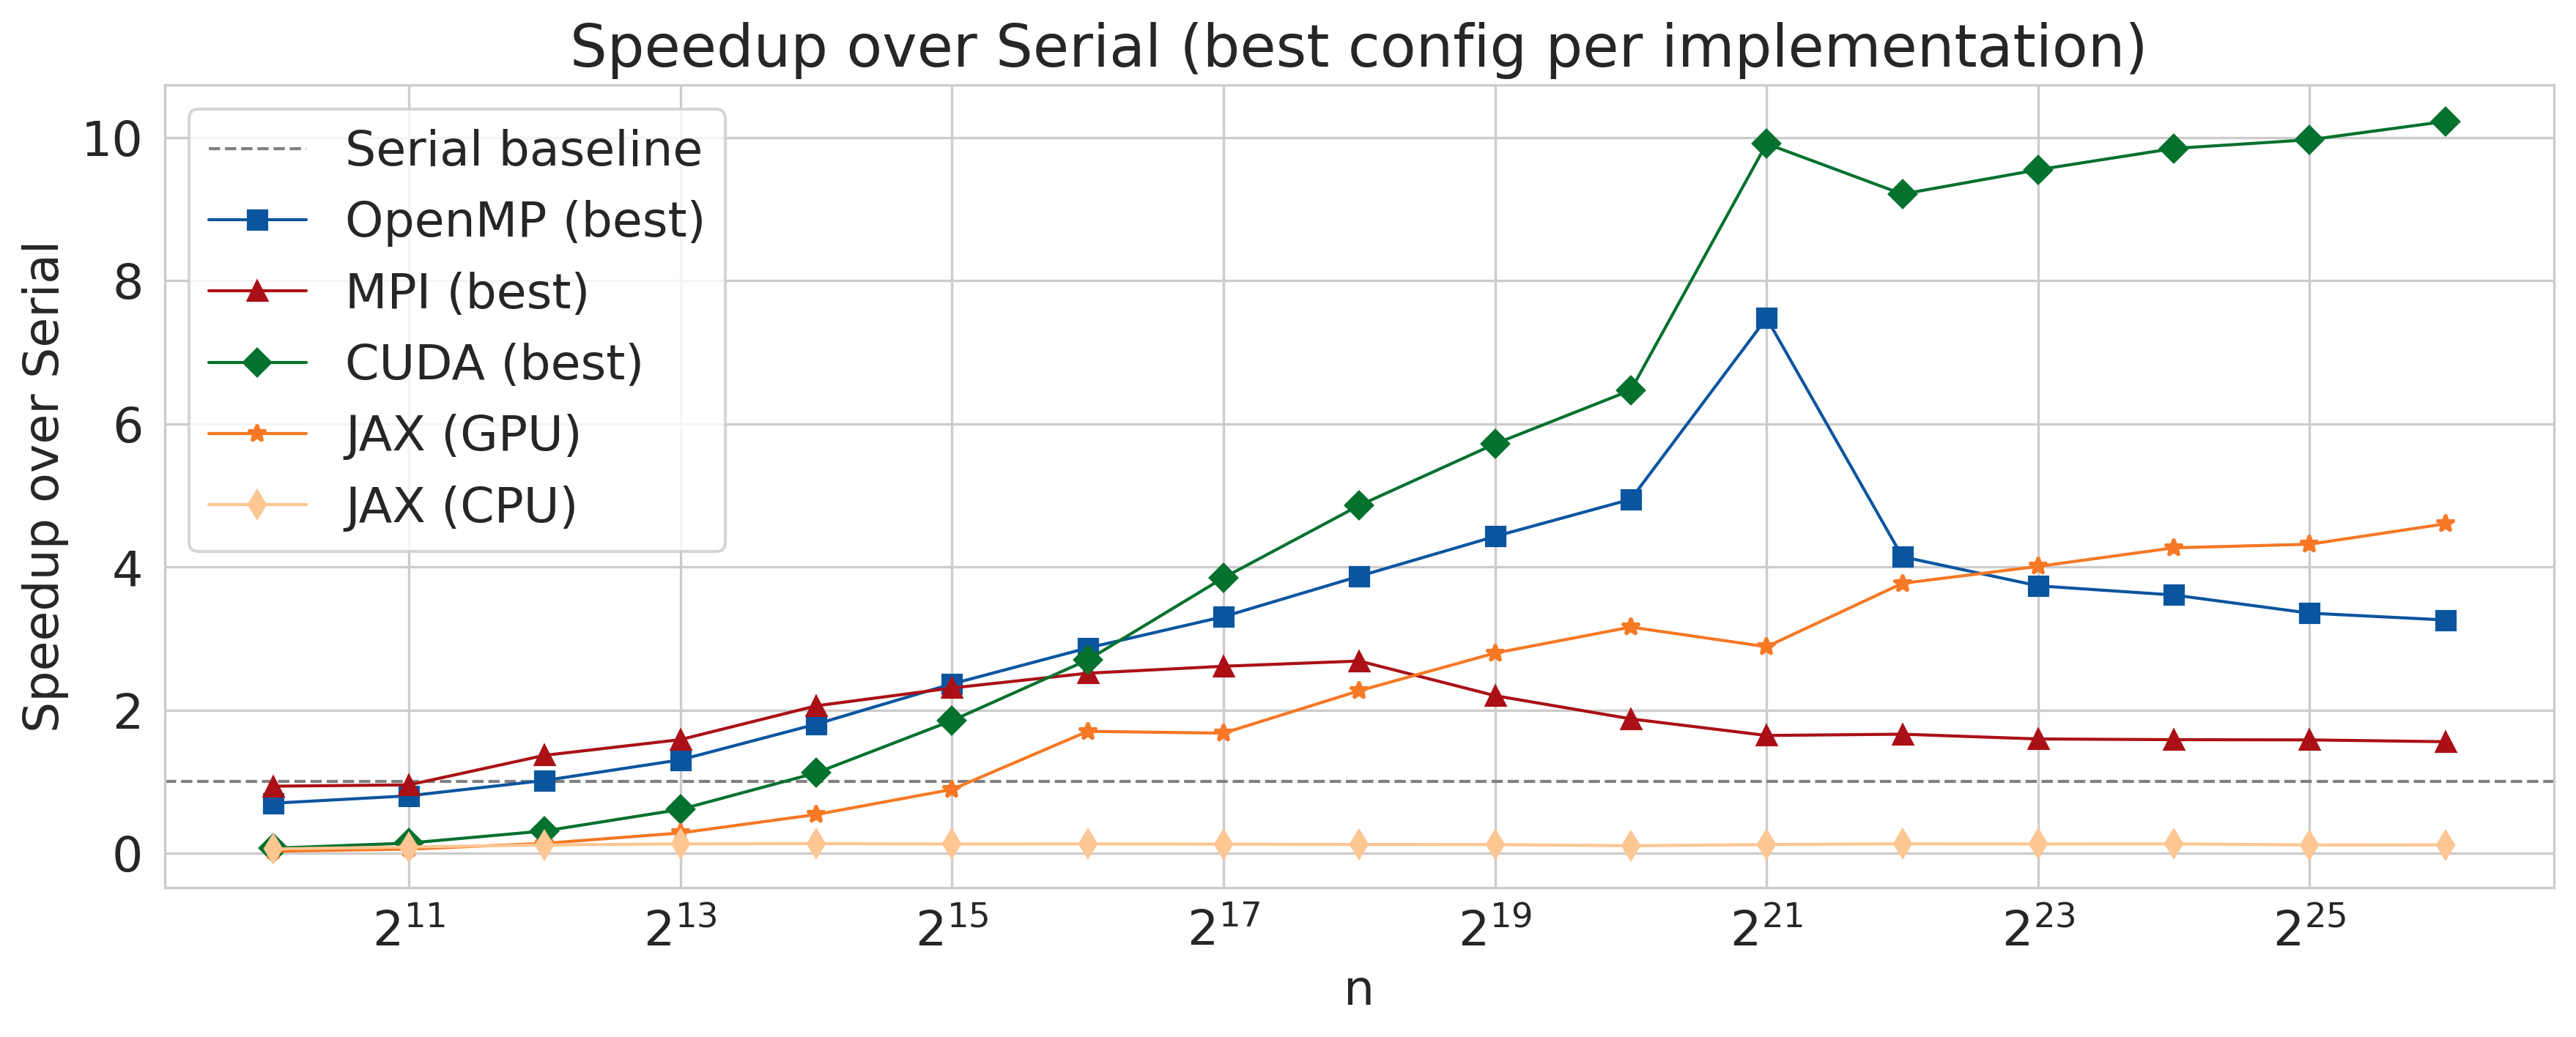

In [73]:
omp_speedup = omp_best.merge(serial_df, on="n", suffixes=("_omp", "_serial"))
mpi_speedup = mpi_best.merge(serial_df, on="n", suffixes=("_mpi", "_serial"))
cuda_speedup = cuda_best.merge(
    serial_df, on="n", suffixes=("_cuda", "_serial")
)
jax_gpu_speedup = jax_gpu_df.merge(
    serial_df, on="n", suffixes=("_jax", "_serial")
)
jax_cpu_speedup = jax_cpu_df.merge(
    serial_df, on="n", suffixes=("_jax", "_serial")
)

fig, ax = plt.subplots()
ax.axhline(y=1, linestyle="--", color="gray", label="Serial baseline")
ax.plot(
    omp_speedup["n"],
    omp_speedup["time_ms_serial"] / omp_speedup["time_ms_omp"],
    marker="s",
    color=omp_col[-1],
    label="OpenMP (best)",
)
ax.plot(
    mpi_speedup["n"],
    mpi_speedup["time_ms_serial"] / mpi_speedup["time_ms_mpi"],
    marker="^",
    color=mpi_col[-1],
    label="MPI (best)",
)
ax.plot(
    cuda_speedup["n"],
    cuda_speedup["time_ms_serial"] / cuda_speedup["time_ms_cuda"],
    marker="D",
    color=cuda_col[-1],
    label="CUDA (best)",
)
ax.plot(
    jax_gpu_speedup["n"],
    jax_gpu_speedup["time_ms_serial"] / jax_gpu_speedup["time_ms_jax"],
    marker="*",
    color=addn_col[3],
    label="JAX (GPU)",
)
ax.plot(
    jax_cpu_speedup["n"],
    jax_cpu_speedup["time_ms_serial"] / jax_cpu_speedup["time_ms_jax"],
    marker="d",
    color=addn_col[1],
    label="JAX (CPU)",
)

ax.set_xscale("log", base=2)
ax.set_xlabel("n")
ax.set_ylabel("Speedup over Serial")
ax.set_title("Speedup over Serial (best config per implementation)")
ax.legend()
plt.tight_layout()
plt.savefig("plots/best_speedup.svg")
plt.show()